# Data Puller

Below is our function to pull data based title, start, and end data. It also has some of our intial EDA on the articles in regards to edit rates

In [1]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [1]:
#run to stop depreceiation errors
#!pip install --upgrade "jupyter_client>=8.4.0" ipykernel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.7/109.7 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.8/118.8 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 18.5 MB/s eta 0:00:00
  Attempting uninstall: jupyter_client
    Found existing installation: jupyter_client 7.4.9
    Uninstalling jupyter_client-7.4.9:
      Successfully uninstalled jupyter_client-7.4.9
  Attempting uninstall: ipykernel
    Found existing installation: ipykernel 6.17.1
    Uninstalling ipykernel-6.17.1:
      Successfully uninstalled ipykernel-6.17.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires ipykernel==6.17.1, but you have ipykernel 7.2.0 which is incompatible.
notebook 6.5.7 requires jupyter-client<8,>=5.3.4, but you have jupyter-client 8.9.0 which is incompatible.
jupyter-kernel-gateway 2.5.2 re

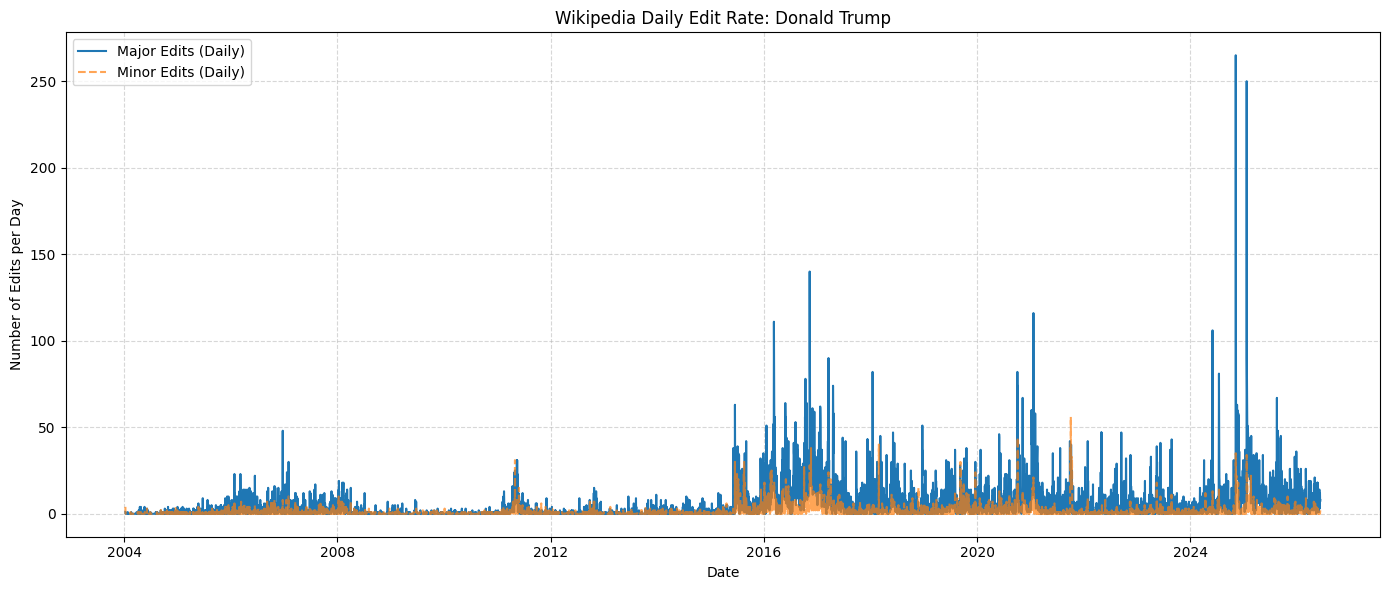

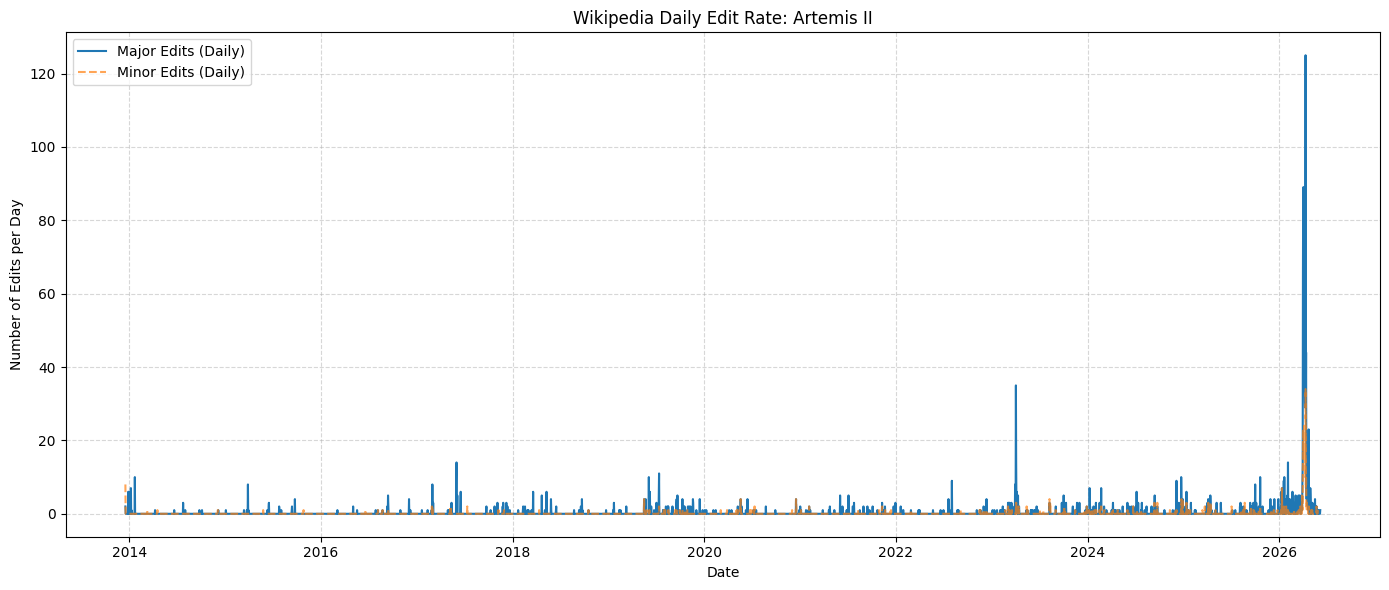

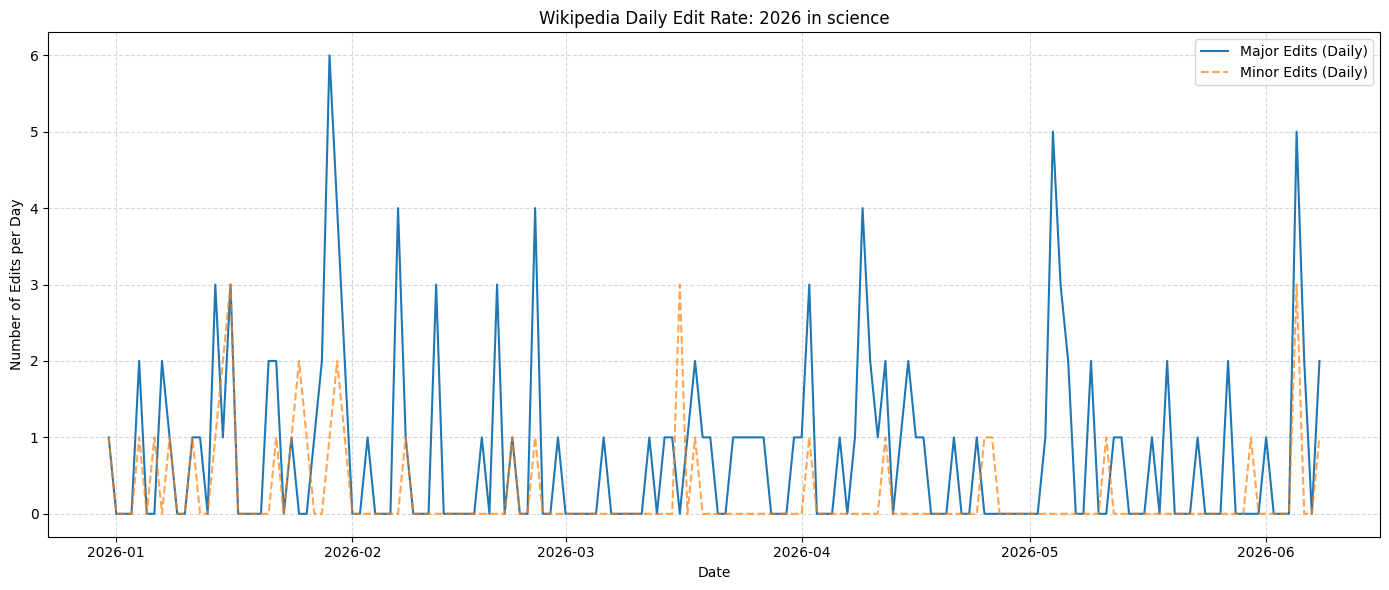

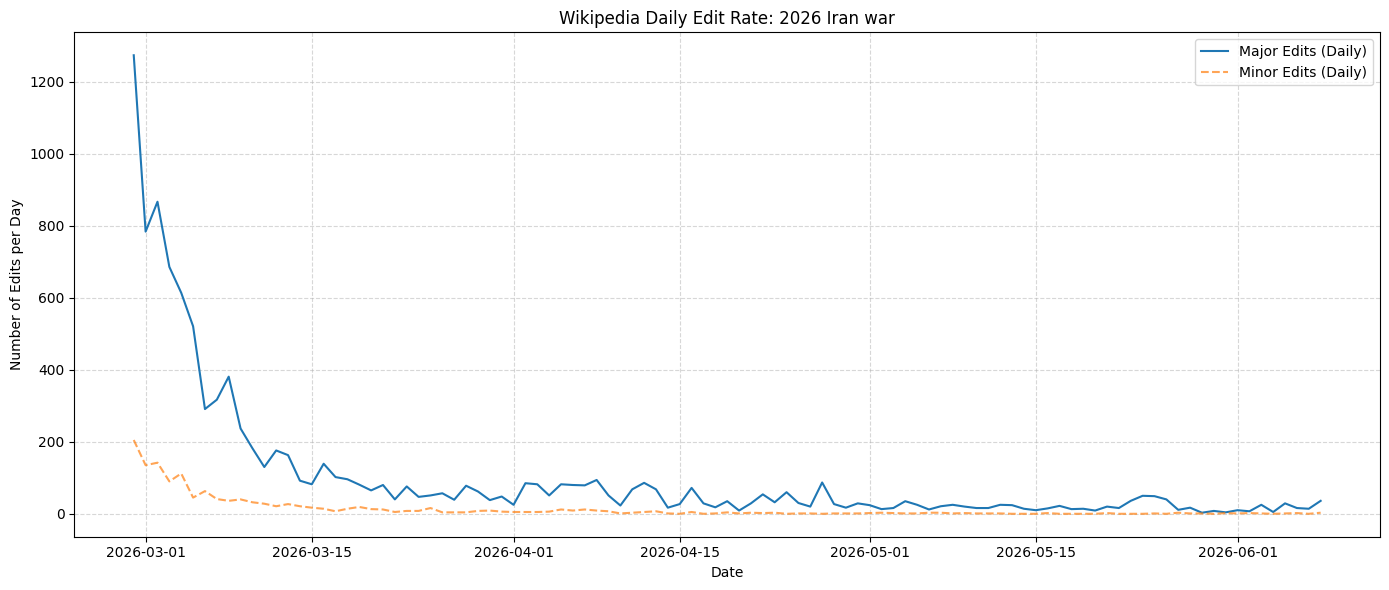

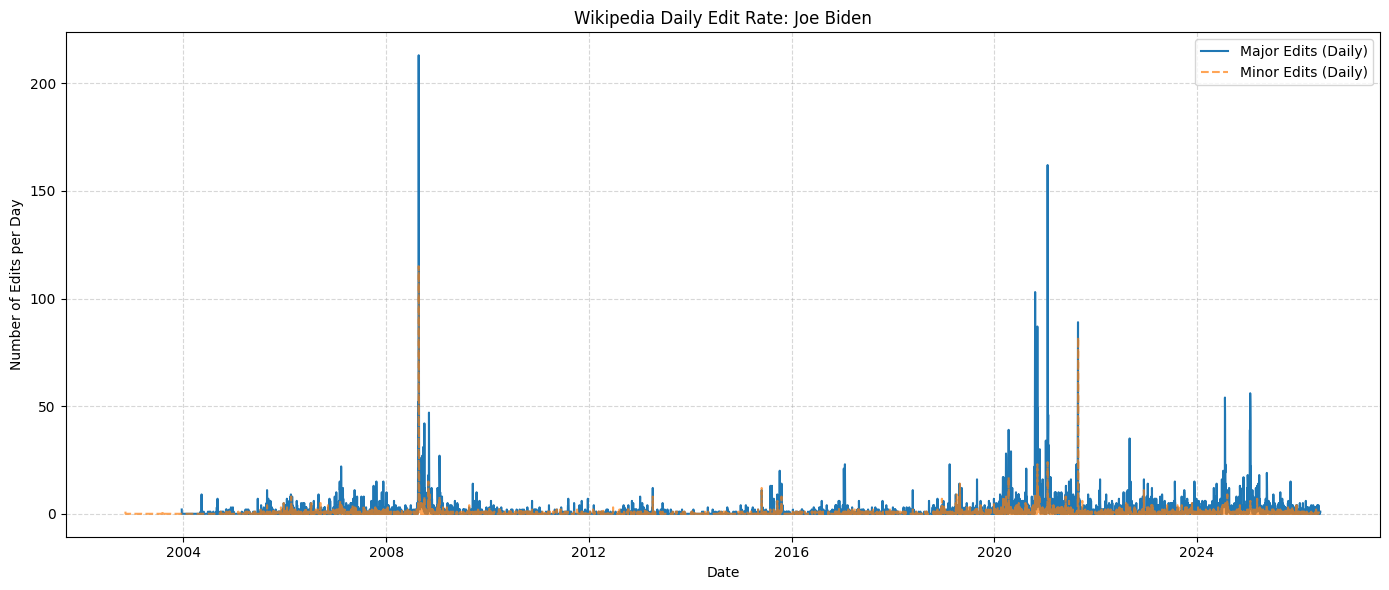

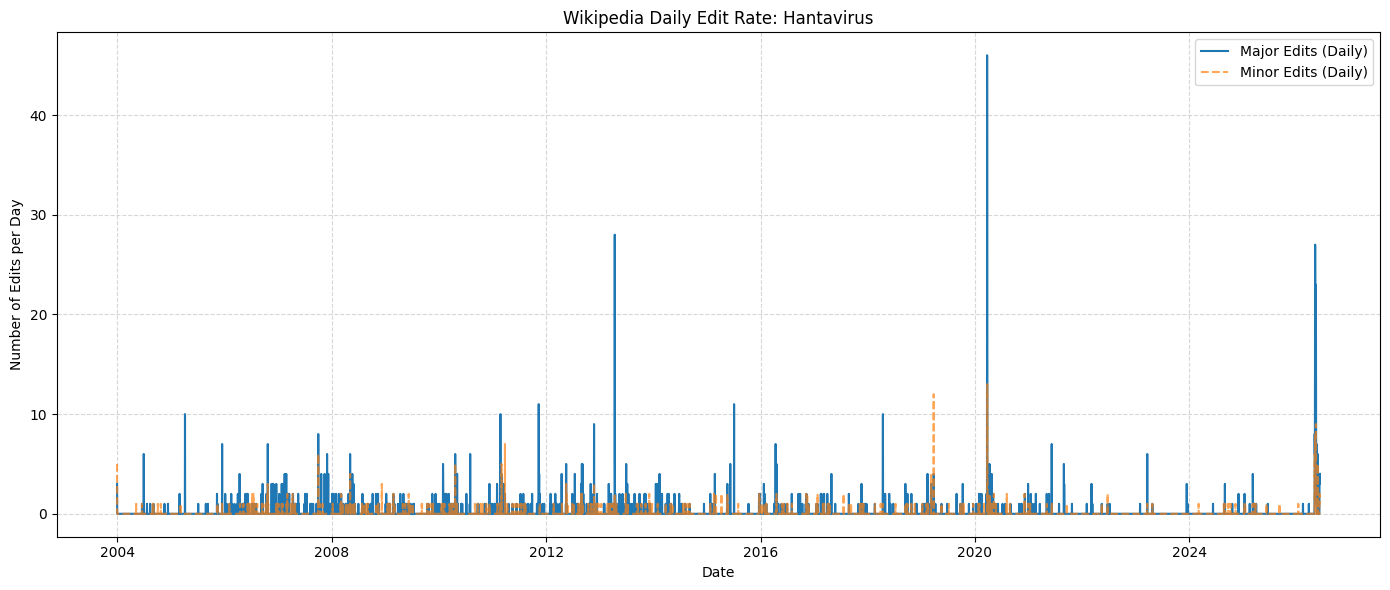

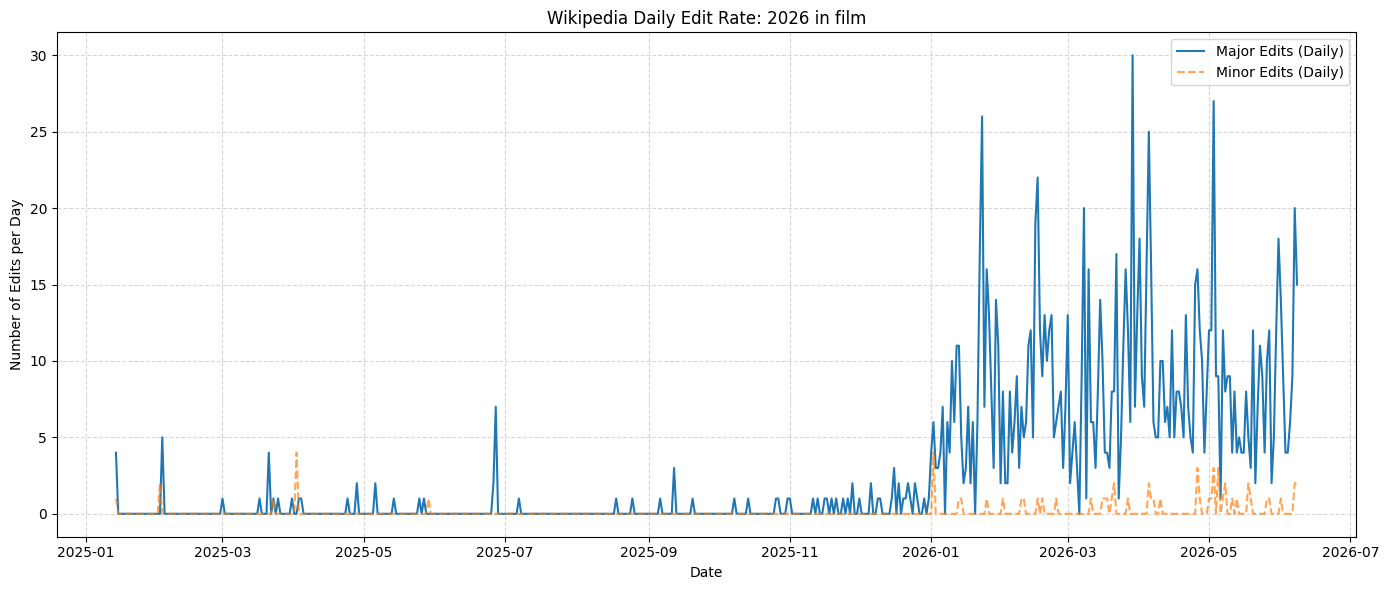

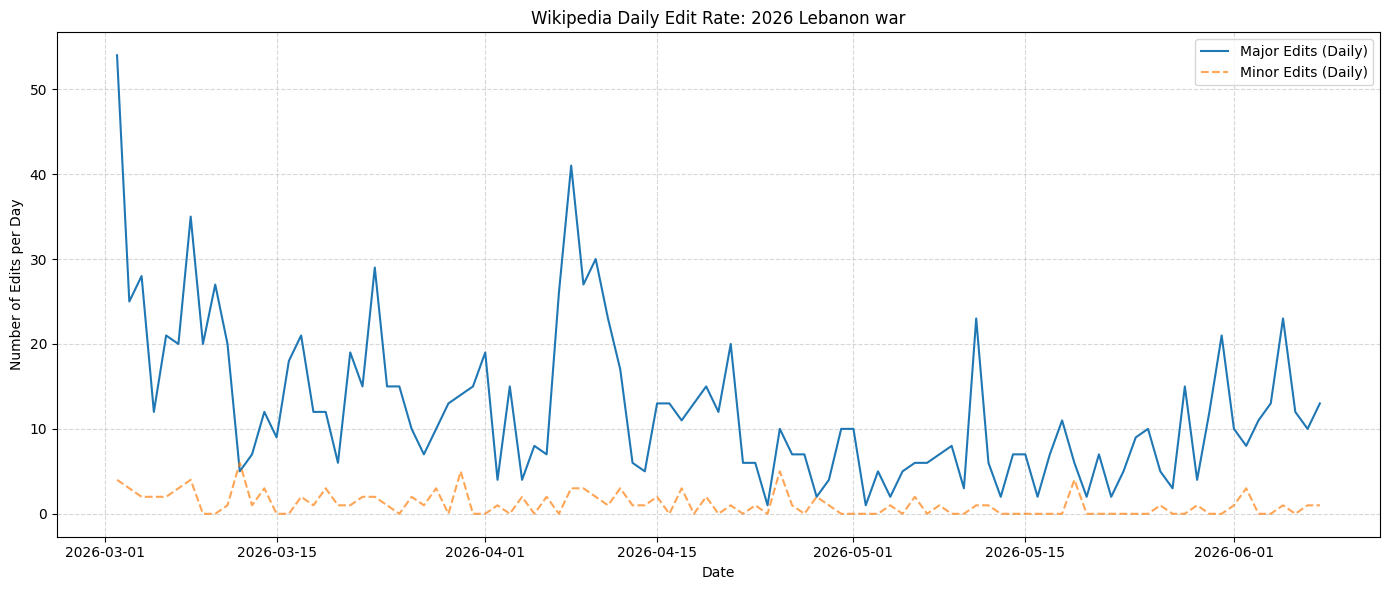

In [2]:
import requests
import pandas as pd
import matplotlib.pyplot as plt


def get_refined_history(title, start_date=None, end_date=None, include_content=False):
    url = "https://en.wikipedia.org/w/api.php"

    headers = {
        'User-Agent': 'EditVisualizerBot/1.0 (cdickersondm@gmail.com)'
    }

    # Base parameters
    params = {
        "action": "query",
        "format": "json",
        "prop": "revisions",
        "titles": title,
        "rvlimit": "max",
        "rvprop": "timestamp|flags|comment",
        "rvdir": "newer"  # Set to 'newer' so we search forward in time
    }

    # Filter for actual edit text if requested
    if include_content:
        params["rvprop"] = "timestamp|flags|comment|content"
        params["rvslots"] = "main"

    # Add date filters if provided
    if start_date:
        params["rvstart"] = f"{start_date}T00:00:00Z"
    if end_date:
        params["rvend"] = f"{end_date}T23:59:59Z"

    revisions = []
    while True:
        response = requests.get(url, params=params, headers=headers).json()

        # Error handling for missing pages
        pages = response.get('query', {}).get('pages', {})
        for p_id in pages:
            page = pages[p_id]
            if "missing" in page:
                print(f"Page '{title}' does not exist.")
                return []

            for rev in page.get('revisions', []):
                rev['category'] = title
                if include_content:
                    rev['text_content'] = rev.get('slots', {}).get('main', {}).get('*', '')
                revisions.append(rev)

        # Check for pagination
        if 'continue' in response:
            params.update(response['continue'])
        else:
            break

    return revisions

topics = ["Donald Trump", "Artemis II", "2026 in science", "2026 Iran war",
          "Joe Biden", "Hantavirus", "2026 in film", "2026 Lebanon war"]
for topic in topics:
    # 1. Fetch data
    data = get_refined_history(topic)
    if not data:
        continue

    df = pd.DataFrame(data)
    df['timestamp'] = pd.to_datetime(df['timestamp'])

    # filter Minor vs Major
    df['is_minor'] = df.apply(lambda x: 1 if 'minor' in x and x['minor'] == '' else 0, axis=1)

    major_edits = df[df['is_minor'] == 0]
    minor_edits = df[df['is_minor'] == 1]

    # aggregation
    major_rate = major_edits.set_index('timestamp').resample('D').size().fillna(0)
    minor_rate = minor_edits.set_index('timestamp').resample('D').size().fillna(0)

    # visualization
    plt.figure(figsize=(14, 6)) # Wider figure for daily detail
    plt.plot(major_rate, label='Major Edits (Daily)', color='#1f77b4', linewidth=1.5)
    plt.plot(minor_rate, label='Minor Edits (Daily)', color='#ff7f0e', linestyle='--', alpha=0.7)

    plt.title(f"Wikipedia Daily Edit Rate: {topic}")
    plt.xlabel("Date")
    plt.ylabel("Number of Edits per Day")
    plt.legend()
    plt.grid(True, which='both', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# EDA


--- Analysis for: Donald Trump ---
Highest Traffic Months:
 - November 2024: 1545 edits
 - November 2016: 1475 edits
 - January 2025: 1187 edits


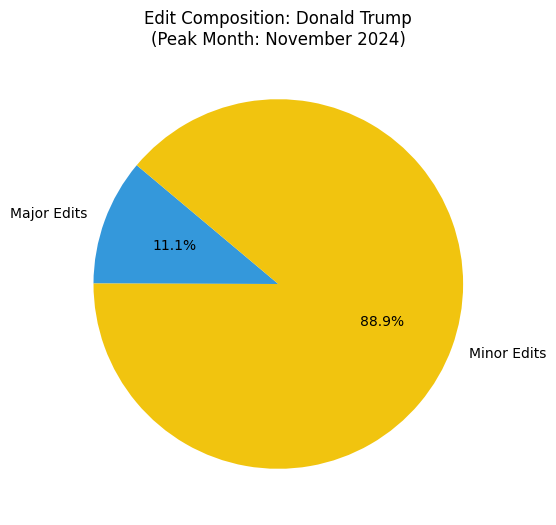


--- Analysis for: Artemis II ---
Highest Traffic Months:
 - April 2026: 1109 edits
 - April 2023: 79 edits
 - January 2026: 76 edits


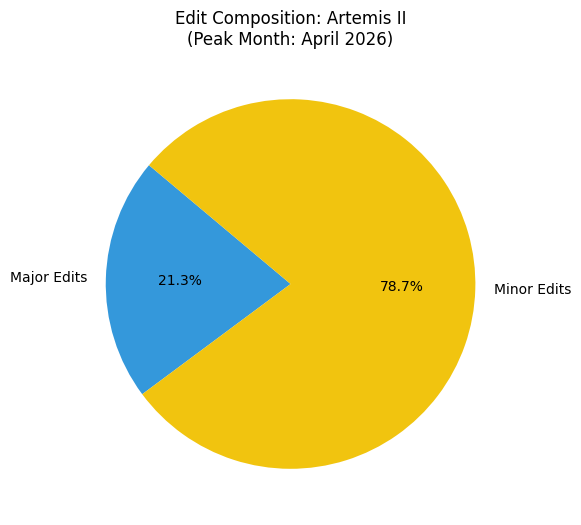


--- Analysis for: 2026 in science ---
Highest Traffic Months:
 - January 2026: 53 edits
 - April 2026: 26 edits
 - May 2026: 23 edits


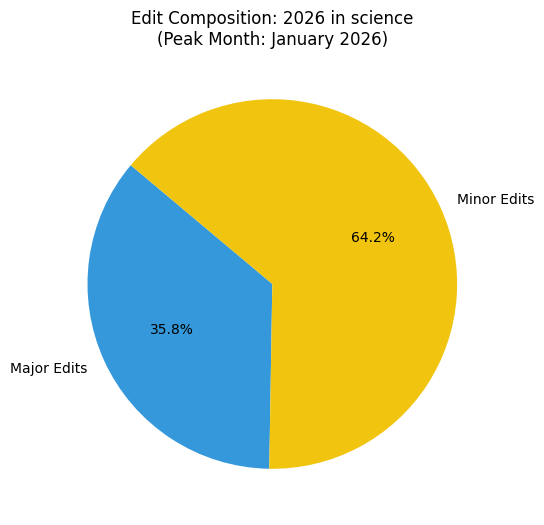


--- Analysis for: 2026 Iran war ---
Highest Traffic Months:
 - March 2026: 7623 edits
 - April 2026: 1577 edits
 - February 2026: 1479 edits


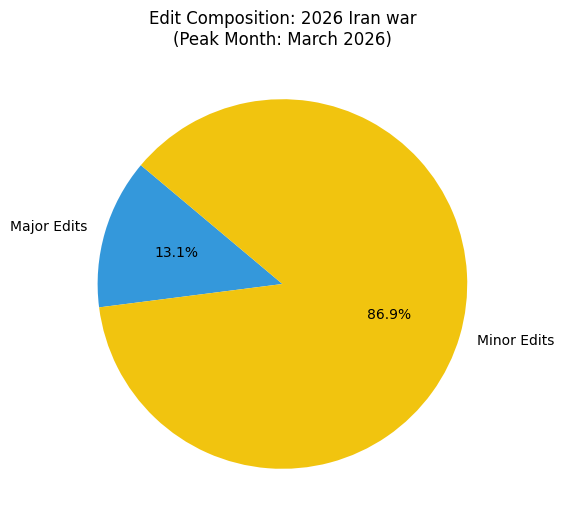


--- Analysis for: Joe Biden ---
Highest Traffic Months:
 - August 2008: 913 edits
 - January 2021: 657 edits
 - November 2020: 535 edits


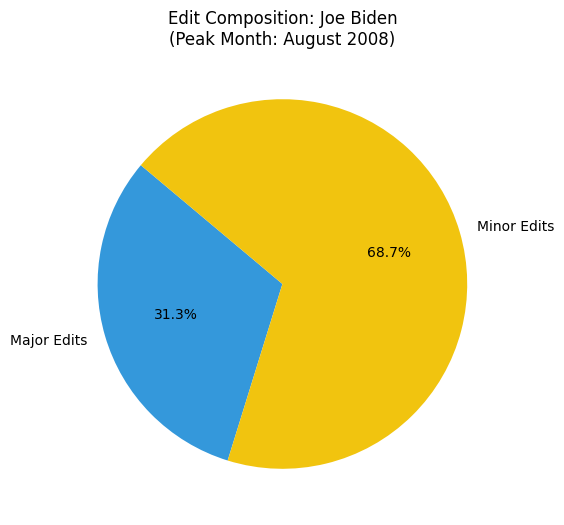


--- Analysis for: Hantavirus ---
Highest Traffic Months:
 - May 2026: 234 edits
 - March 2020: 103 edits
 - April 2013: 44 edits


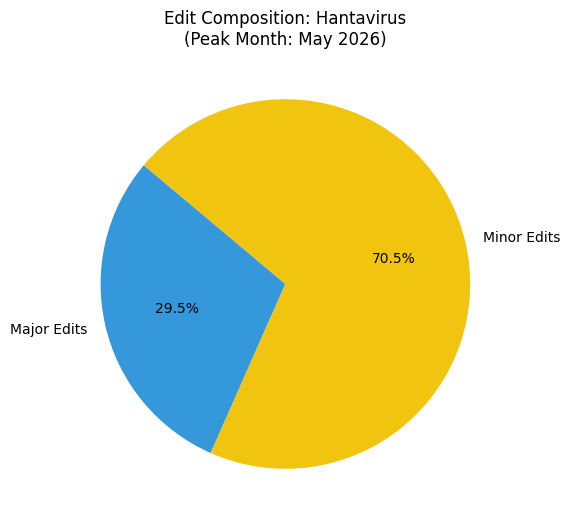


--- Analysis for: 2026 in film ---
Highest Traffic Months:
 - April 2026: 293 edits
 - May 2026: 275 edits
 - March 2026: 274 edits


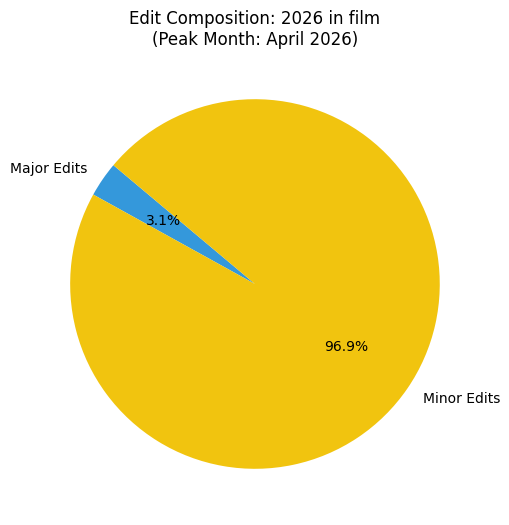


--- Analysis for: 2026 Lebanon war ---
Highest Traffic Months:
 - March 2026: 581 edits
 - April 2026: 419 edits
 - May 2026: 231 edits


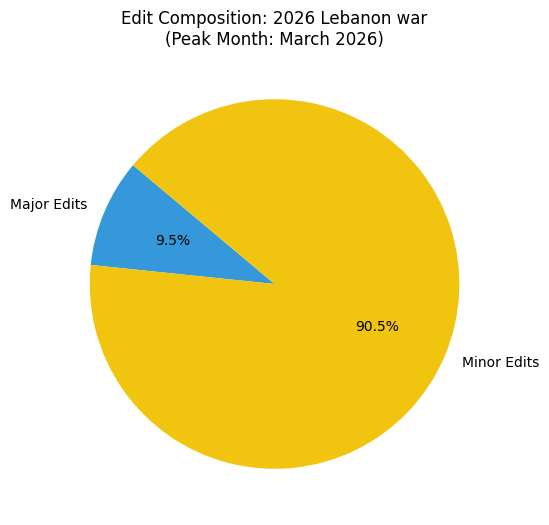

In [3]:
for topic in topics:
    data = get_refined_history(topic)
    if not data:
        continue

    df = pd.DataFrame(data)
    df['timestamp'] = pd.to_datetime(df['timestamp'])

    #Get total edits per month
    monthly_counts = df.set_index('timestamp').resample('ME').size()

    # Find peaks
    top_months = monthly_counts.nlargest(3)

    print(f"\n--- Analysis for: {topic} ---")
    print("Highest Traffic Months:")
    for date, count in top_months.items():
        print(f" - {date.strftime('%B %Y')}: {count} edits")

    # focus on peak month
    peak_month_ts = top_months.index[0]
    peak_month_data =peak_month_data = df[df['timestamp'].dt.tz_localize(None).dt.to_period('M') == peak_month_ts.tz_localize(None).to_period('M')]

    # Categorize edits in that specific peak month
    major_peak = peak_month_data[~peak_month_data.get('minor', False).astype(bool)]
    minor_peak = peak_month_data[peak_month_data.get('minor', False).astype(bool)]

    # Visulaize the distribution during that peak month
    labels = ['Major Edits', 'Minor Edits']
    sizes = [len(major_peak), len(minor_peak)]

    plt.figure(figsize=(6, 6))
    plt.pie(sizes, labels=labels, autopct='%1.1f%%', colors=['#3498db', '#f1c40f'], startangle=140)
    plt.title(f"Edit Composition: {topic}\n(Peak Month: {peak_month_ts.strftime('%B %Y')})")
    plt.show()

# Edit rate analysis
Here we started to analyze the edit rates of the peak months of the article to closer analyze what might be causing edit rate spikes.

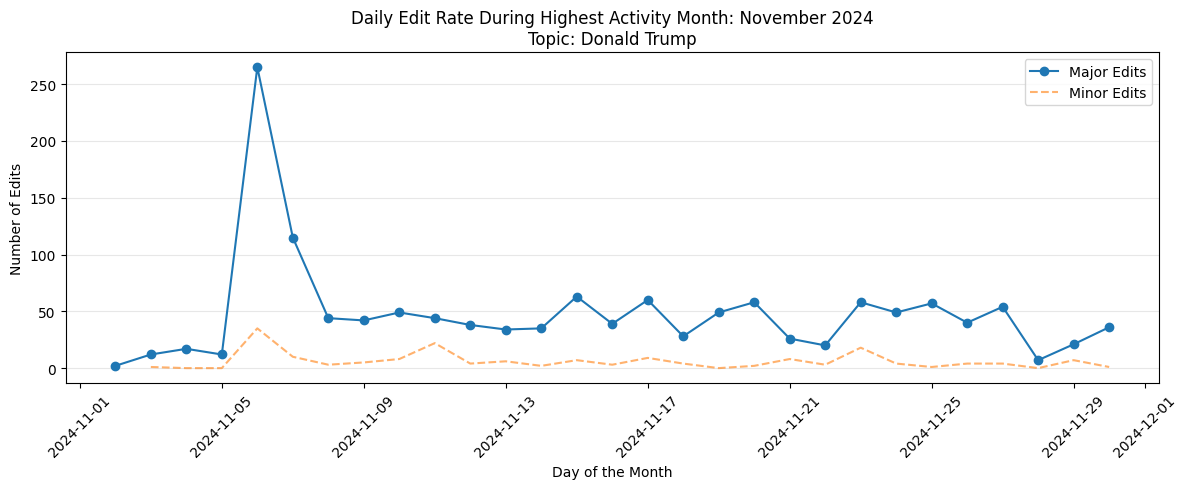

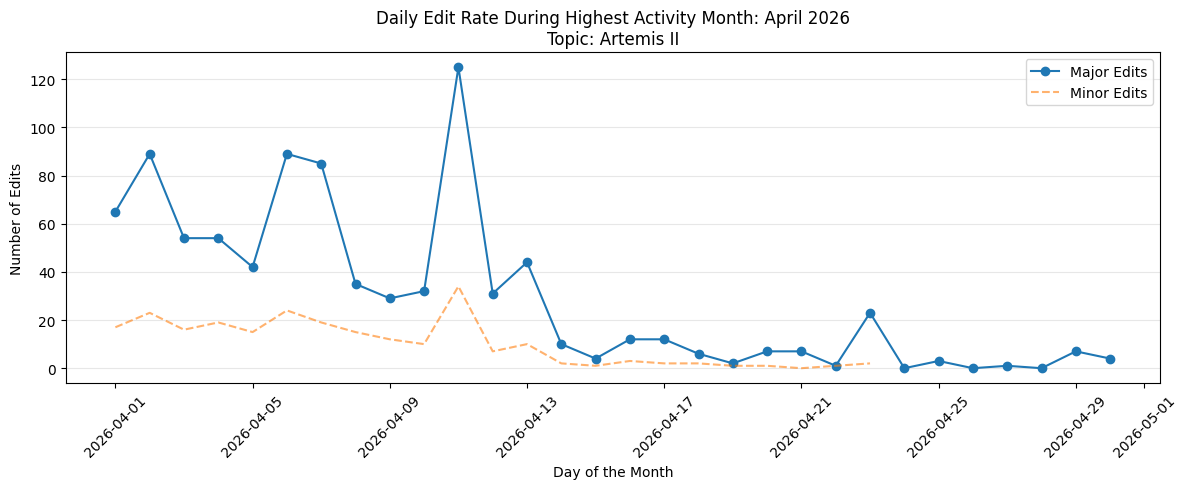

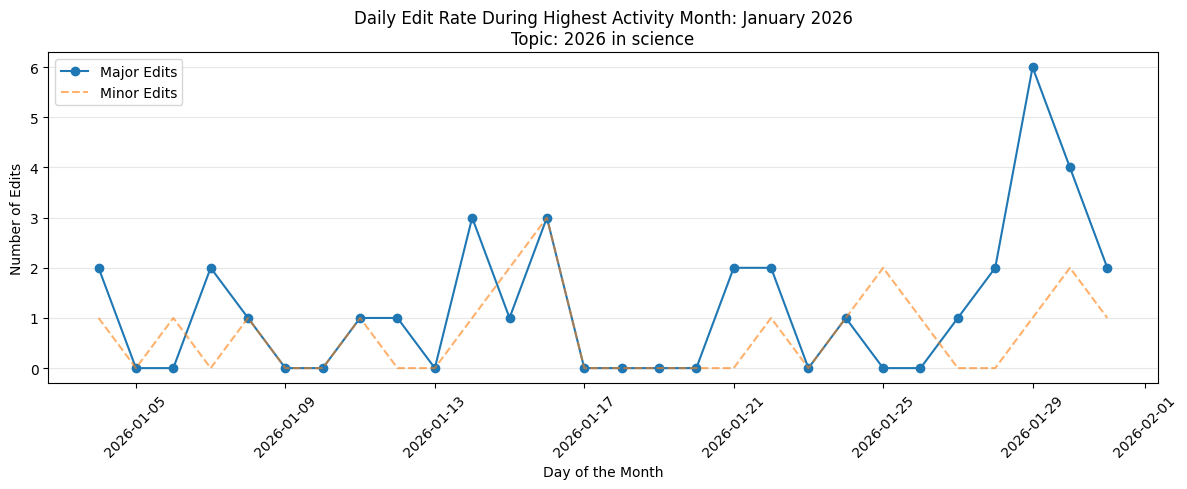

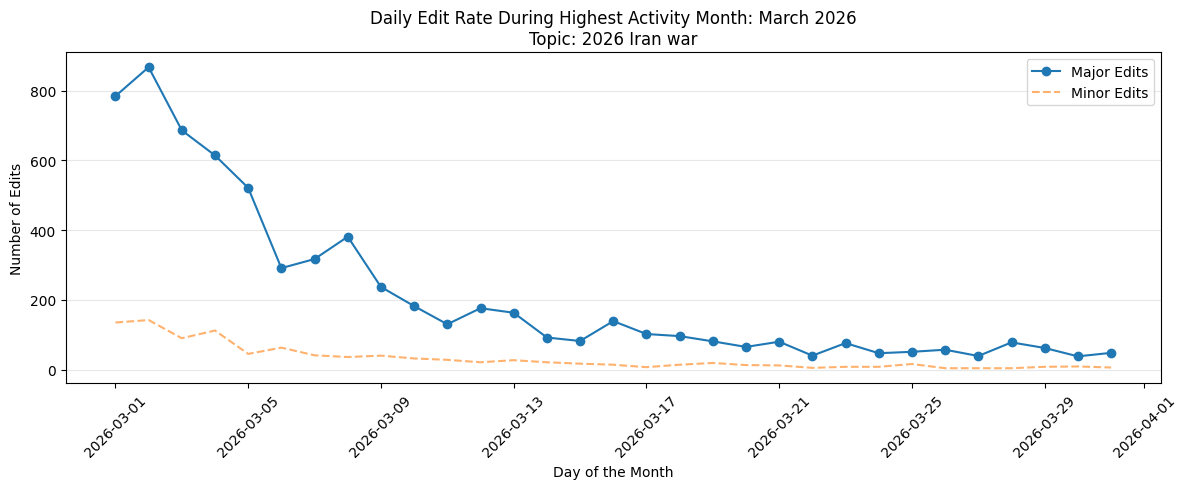

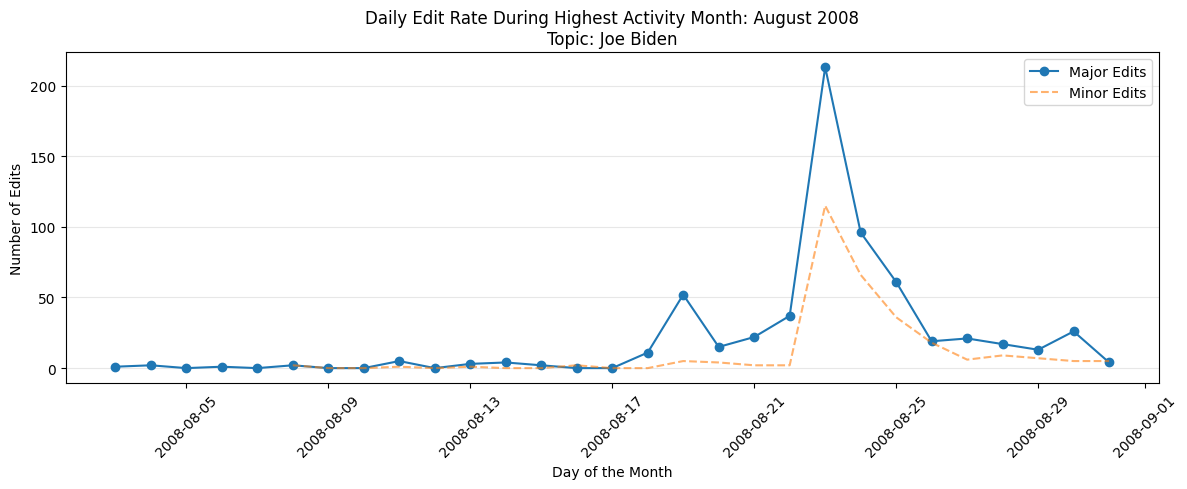

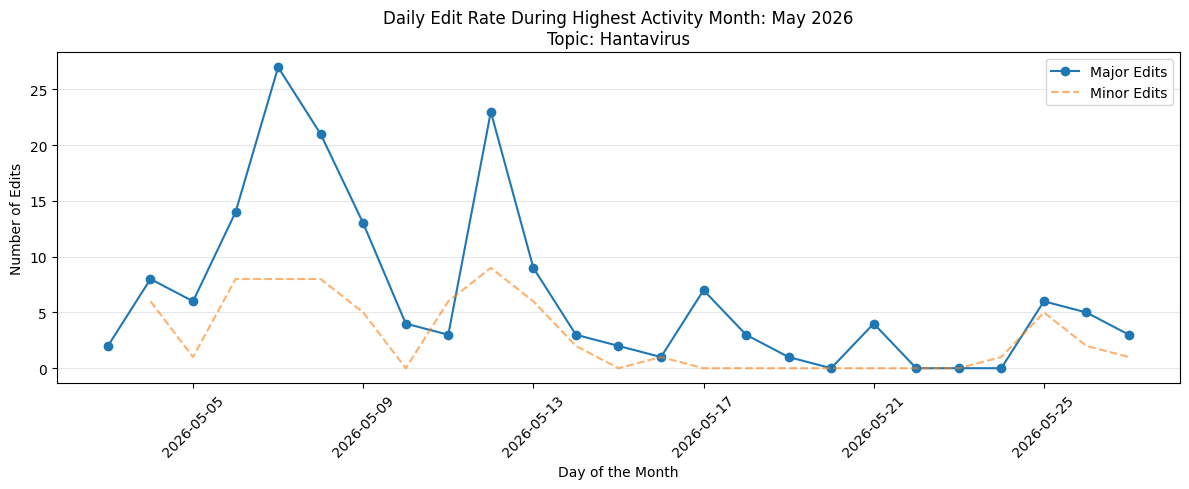

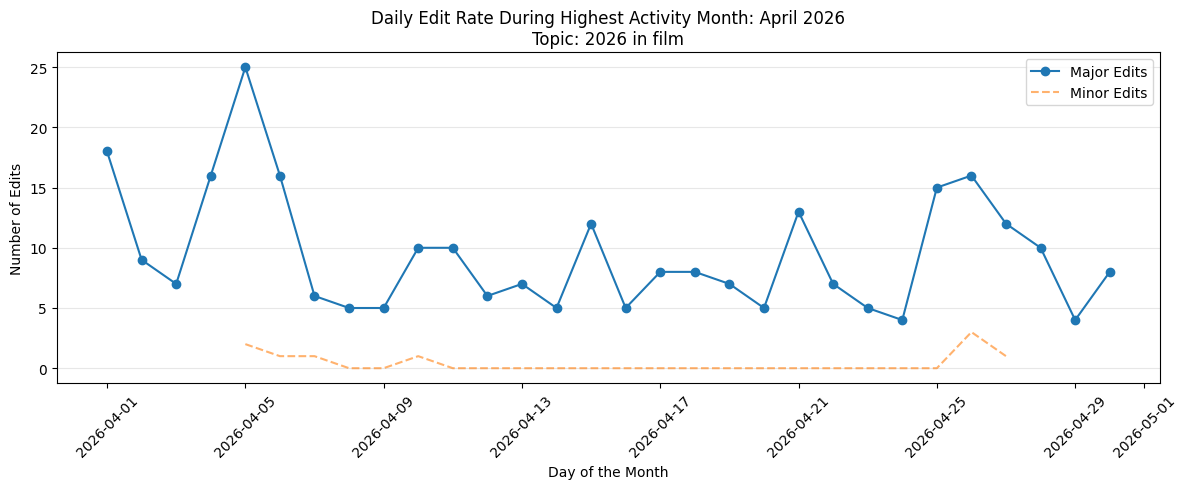

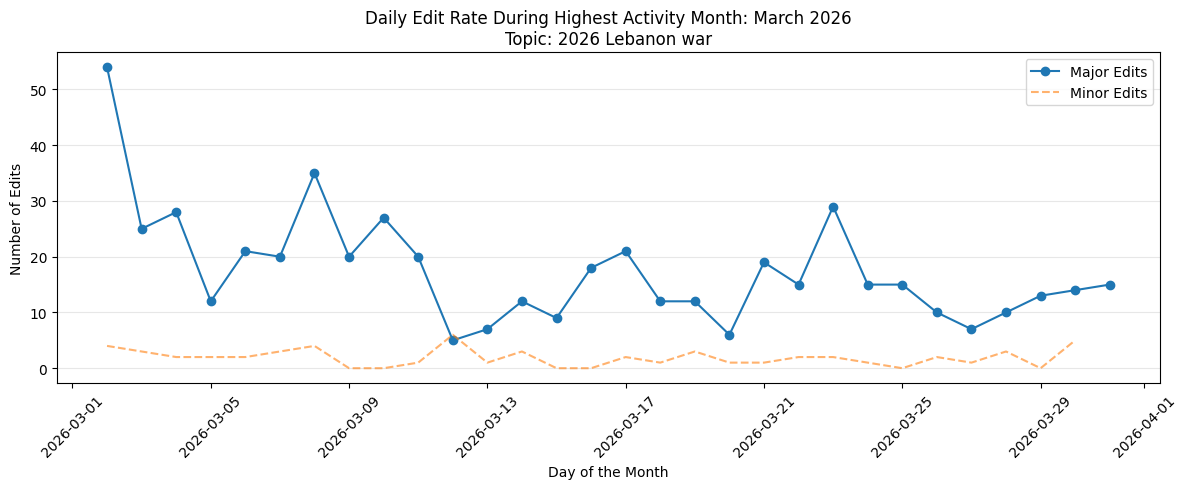

In [5]:
for topic in topics:
    data = get_refined_history(topic)
    if not data:
        continue

    df = pd.DataFrame(data)
    df['timestamp'] = pd.to_datetime(df['timestamp'])

    # Split Major and Minor
    df['is_minor'] = df.apply(lambda x: 1 if 'minor' in x and x['minor'] == '' else 0, axis=1)

    # Group by month
    major_edits = df[df['is_minor'] == 0]
    if major_edits.empty:
        print(f"No major edits found for {topic}.")
        continue

    # Find the month label (YYYY-MM) with the max count
    peak_month = major_edits.set_index('timestamp').resample('ME').size().idxmax()

    # Filter for peak month
    mask = (df['timestamp'].dt.year == peak_month.year) & (df['timestamp'].dt.month == peak_month.month)
    df_peak = df[mask].copy()

    # aggregate
    daily_major = df_peak[df_peak['is_minor'] == 0].set_index('timestamp').resample('D').size()
    daily_minor = df_peak[df_peak['is_minor'] == 1].set_index('timestamp').resample('D').size()

    # plot
    plt.figure(figsize=(12, 5))
    plt.plot(daily_major, label='Major Edits', marker='o', color='#1f77b4')
    plt.plot(daily_minor, label='Minor Edits', linestyle='--', alpha=0.6, color='#ff7f0e')

    month_name = peak_month.strftime('%B %Y')
    plt.title(f"Daily Edit Rate During Highest Activity Month: {month_name}\nTopic: {topic}")
    plt.ylabel("Number of Edits")
    plt.xlabel("Day of the Month")
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Here we began to look at specific times other than peak months to look for patterns around known events that we theorized would cause an increase in edit rates.

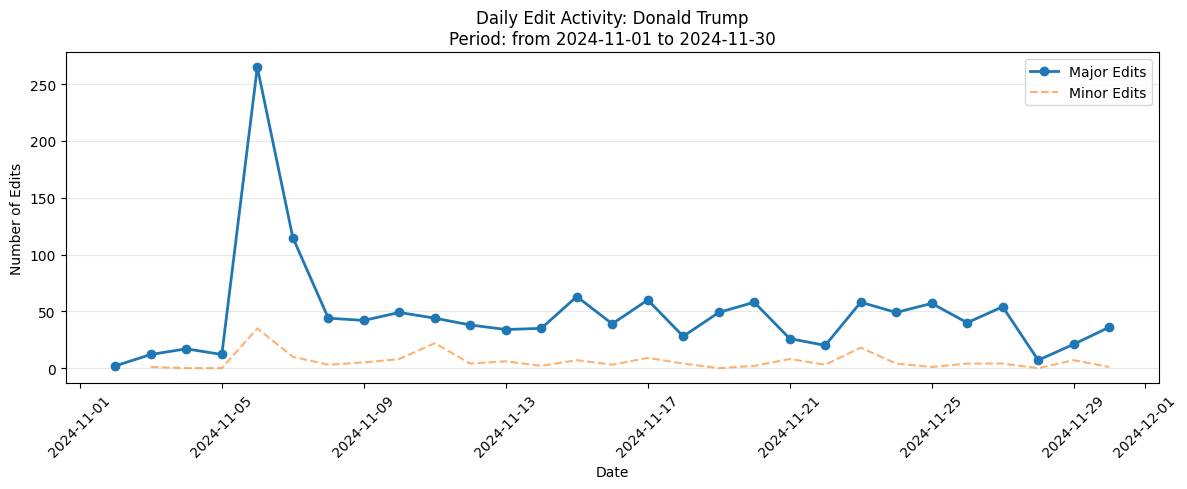

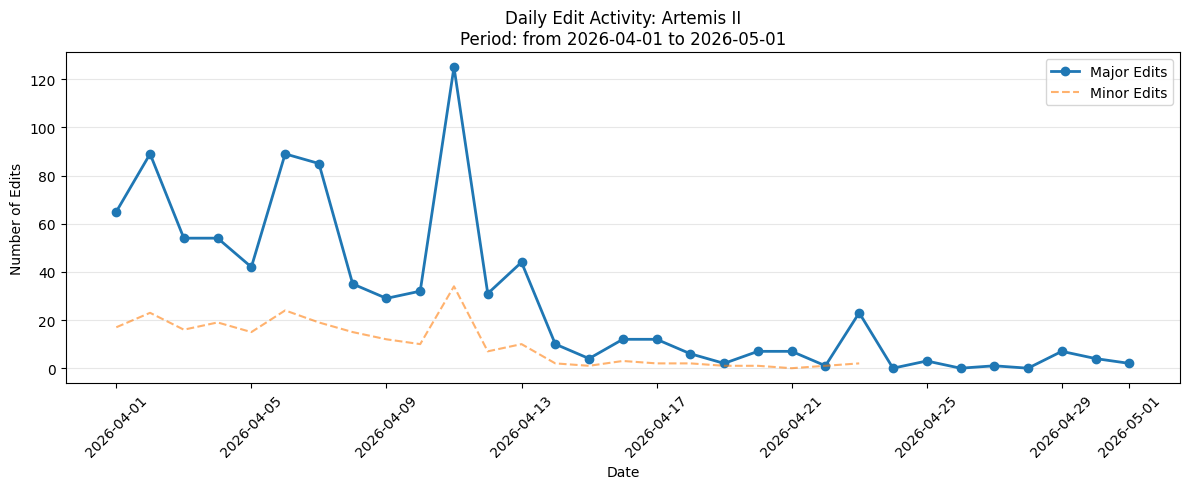

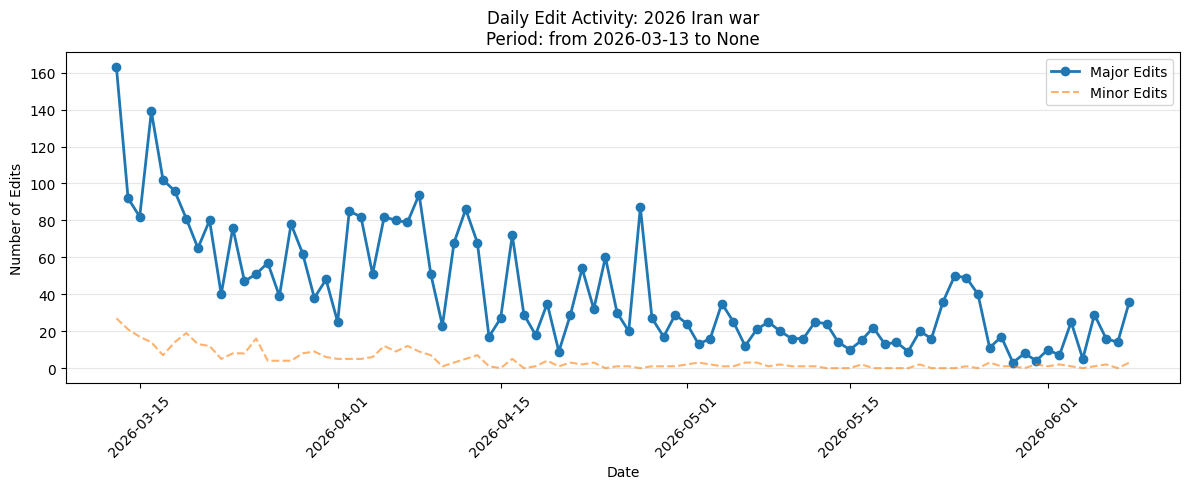

Skipping Joe Biden: No data found for the period 2008-08-01 to 2008-06-31.


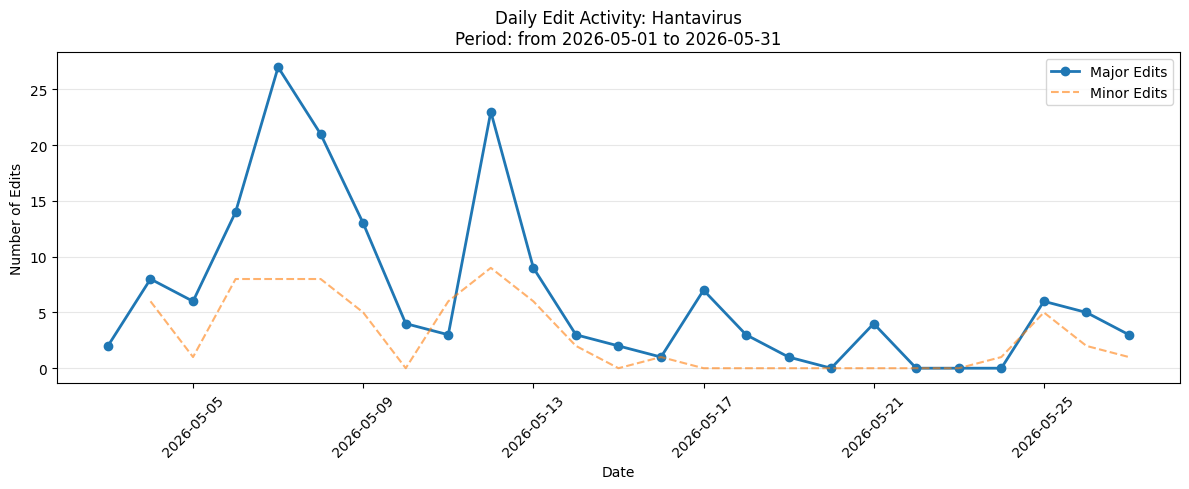

Skipping 2026 in film: No data found for the period 2016-04-01 to 2016-04-30.


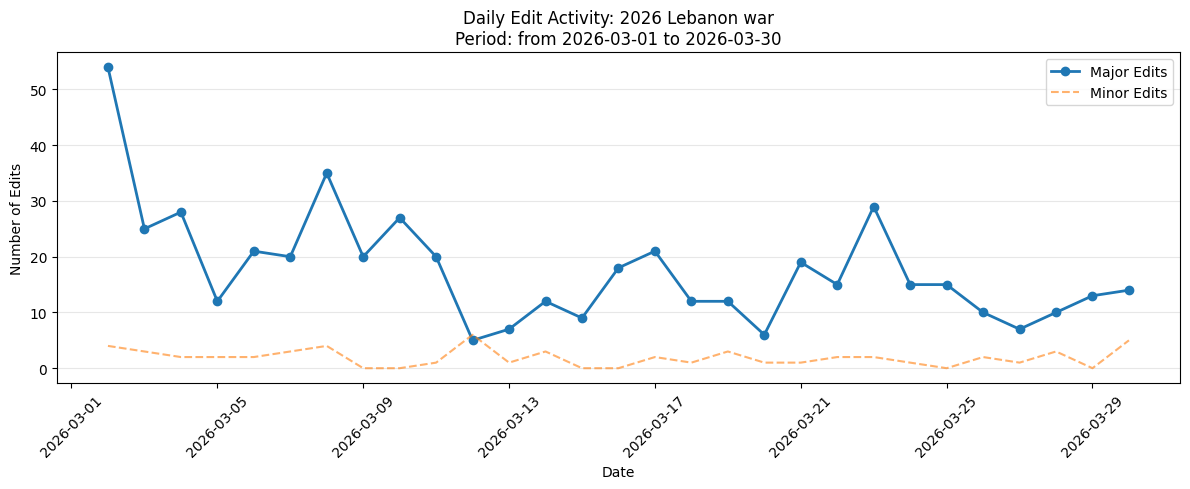

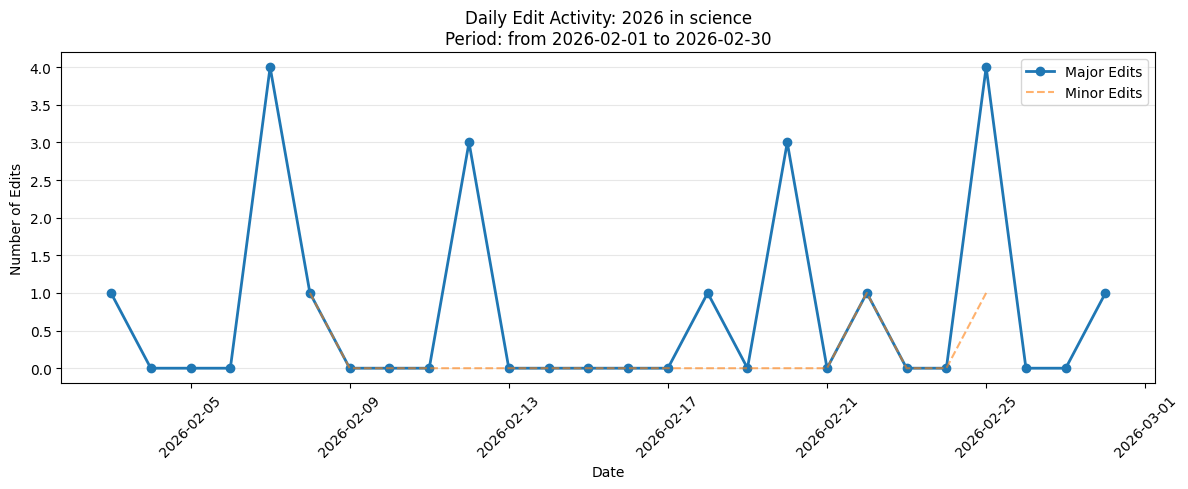

In [6]:
topics_config = [
    {"title": "Donald Trump", "start": "2024-11-01", "end": "2024-11-30"},
    {"title": "Artemis II", "start": "2026-04-01", "end": "2026-05-01"},
    {"title": "2026 Iran war","start": "2026-03-13","end": None},
    {"title": "Joe Biden", "start": "2008-08-01", "end": "2008-06-31"},
    {"title": "Hantavirus", "start": "2026-05-01", "end": "2026-05-31"},
    {"title": "2026 in film", "start": "2016-04-01", "end": "2016-04-30"},
    {"title": "2026 Lebanon war", "start": "2026-03-01", "end": "2026-03-30"},
    {"title": "2026 in science", "start": "2026-02-01", "end": "2026-02-30"}
]

for item in topics_config:
    topic = item["title"]
    start = item["start"]
    end = item["end"]

    # Fetch data
    data = get_refined_history(topic, start_date=start, end_date=end)

    if not data:
        print(f"Skipping {topic}: No data found for the period {start} to {end}.")
        continue

    df = pd.DataFrame(data)
    df['timestamp'] = pd.to_datetime(df['timestamp'])

    # Split major and minor
    df['is_minor'] = df.apply(lambda x: 1 if 'minor' in x and x['minor'] == '' else 0, axis=1)

    # aggregate
    daily_major = df[df['is_minor'] == 0].set_index('timestamp').resample('D').size()
    daily_minor = df[df['is_minor'] == 1].set_index('timestamp').resample('D').size()

    # plot
    plt.figure(figsize=(12, 5))

    plt.plot(daily_major, label='Major Edits', marker='o', color='#1f77b4', linewidth=2)
    plt.plot(daily_minor, label='Minor Edits', linestyle='--', alpha=0.6, color='#ff7f0e')

    date_label = f"from {start} to {end}" if start else "Full History"
    plt.title(f"Daily Edit Activity: {topic}\nPeriod: {date_label}")

    plt.ylabel("Number of Edits")
    plt.xlabel("Date")
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Donald Trump Analysis

We wanted to see what was popular in comments so we could better understand the commenting syntax and identify any signs of vandalism. We though to analyze Donald Trump as we hypothesized he would be a controvesral figure

In [ ]:
# Retrieve Donald Trump revision comments for November 2024
df = pd.DataFrame(
    get_refined_history(
        'Donald Trump',
        start_date='2024-11-01',
        end_date='2024-11-30'
    )
)

df['timestamp'] = pd.to_datetime(df['timestamp'])
df['is_minor'] = df.apply(lambda x: 1 if 'minor' in x and x['minor'] == '' else 0, axis=1)

df.head()

In [ ]:
import re
import html

def clean_edit_comment(text):
    text = str(text)

    # Decode HTML entities twice in case comments are double-escaped
    text = html.unescape(html.unescape(text))

    # Replace non-breaking spaces with normal spaces
    text = text.replace('\xa0', ' ')

    # Remove Wikipedia edit section markers, like /* Background */
    text = re.sub(r'/\*.*?\*/', ' ', text)

    # Remove URLs
    text = re.sub(r'https?://\S+', '', text)

    # Convert internal links to display text
    text = re.sub(r'\[\[(?:[^|\]]*\|)?([^\]]+)\]\]', r'\1', text)

    # Remove hashtags but keep the word
    text = re.sub(r'#(\w+)', r'\1', text)

    # Keep letters, numbers, and spaces
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)

    # Clean whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text.lower()

df['clean_text'] = df['comment'].fillna('').apply(clean_edit_comment)

In [ ]:
# Import the 'nltk' package
import nltk
# Download ancillary nltk 'stopwords' if not already installed
nltk.download('stopwords')

# Import the necessary packages
from nltk.corpus import stopwords
from collections import Counter

In [ ]:
# Use regex to tokenize every word/ extract every sequence of word characters
tokens = [w for post in df['clean_text'] for w in re.findall(r'\w+', str(post))]
# Convert to lowercase in 'tokens_lower'
tokens_lower = [token.lower() for token in tokens]

# Filter words in 'tokens_lower' list without stopwords
filtered = [w for w in tokens_lower if not w in stopwords.words('english')]

# Count the frequencies of tokens in 'filtered'
count = Counter(filtered)
print(count.most_common(20))

# Split into words and frequencies
most_common = count.most_common(20)
words, frequencies = zip(*most_common)

# Plot a bar chart to visualize the top 20 most frequent words in the dataset
plt.figure(figsize=(20, 10))
plt.bar(words, frequencies)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Words for Donald Trump Edit Comments (November 2024)')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [ ]:
# Import 'ngrams' from 'nltk.util'
from nltk.util import ngrams

In [ ]:
# Create a list of lists/ one list of tokens for each post
tokenized_docs = []

# For every 'post' in the 'clean_text' column
for post in df['clean_text']:
    # Use regex to tokenize every word/ extract every sequence of word characters
    words = re.findall(r'\w+', str(post))
    # Convert to lowercase in 'words_lower'
    words_lower = [w.lower() for w in words]
    # Filter 'words_lower' without stopwords
    filtered_words = [w for w in words_lower if w not in stopwords.words('english')]
    # Append each 'filtered_words' list for every 'post' to 'tokenized_docs' list
    tokenized_docs.append(filtered_words)

# Create a list of unigrams
unigrams = [word for doc in tokenized_docs for word in doc]

# Create an empty list of bigrams
bigrams = []

# Create bigrams within each post only
for doc in tokenized_docs:
  # For each sliding window/ tuple of size 2
  for window in ngrams(doc, 2):
    # Append each tuple to 'bigrams'
    bigrams.append(window)

# Count the frequencies of unigrams and bigrams
unigram_counts = Counter(unigrams).most_common(20)
bigram_counts = Counter(bigrams).most_common(20)

# Create an empty list of joined bigram phrases
# Join the separate words in each tuple into one phrase
bigram_counts_join = []

# For each tuple in bigram_counts
for bigram in bigram_counts:
    # Join the first element of the tuple into one phrase
    bigram_join = ' '.join(bigram[0])
    # Keep the second element of the tuple/ frequency count
    count = bigram[1]
    # Append the the new tuple of bigram phrase and count to list
    bigram_counts_join.append((bigram_join, count))

# Split into unigrams and frequencies
ug_words, ug_freqs = zip(*unigram_counts)
# Split into bigrams and frequencies
bg_words, bg_freqs = zip(*bigram_counts_join)

# Visualize the frequency outcomes for unigrams
plt.figure(figsize=(20, 10))
plt.bar(ug_words, ug_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Unigrams for Donald Trump Edit Comments (November 2024)')
plt.xlabel('Unigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Visualize the frequency outcomes for bigrams
plt.figure(figsize=(20, 10))
plt.bar(bg_words, bg_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Bigrams for Donald Trump Edit Comments (November 2024)')
plt.xlabel('Bigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


In [ ]:
# Import the necessary packages
import math
import string

In [ ]:
# Define TF function as reviewed in class
def computeTF(wordDict, bagOfWords):
    tfDict = {}
    bagOfWordsCount = len(bagOfWords)
    for word, count in wordDict.items():
        tfDict[word] = count / float(bagOfWordsCount) if bagOfWordsCount > 0 else 0
    return tfDict

# Define IDF function as reviewed in class
def computeIDF(documents):
    N = len(documents)
    idfDict = dict.fromkeys(documents[0].keys(), 0)
    for document in documents:
        for word, val in document.items():
            if val > 0:
                idfDict[word] += 1
    for word, val in idfDict.items():
        idfDict[word] = math.log(N / float(val)) if val > 0 else 0
    return idfDict

# Define TF-IDF function as reviewed in class
def computeTFIDF(tfBagOfWords, idfs):
    tfidf = {}
    for word, val in tfBagOfWords.items():
        tfidf[word] = val * idfs[word]
    return tfidf

# Define TF-IDF DataFrame function as reviewed in class
def get_tfidf_dataframe(tokenized_docs):
    # Step A: Build global vocabulary
    vocabulary = set()
    for doc in tokenized_docs:
        vocabulary = vocabulary.union(set(doc))

    # Step B: Count words per document
    word_dicts = []
    for doc in tokenized_docs:
        word_dict = dict.fromkeys(vocabulary, 0)
        for word in doc:
            word_dict[word] += 1
        word_dicts.append(word_dict)

    # Step C: Compute TF
    tf_list = []
    for i in range(len(tokenized_docs)):
        tf_list.append(computeTF(word_dicts[i], tokenized_docs[i]))

    # Step D: Compute IDF
    idfs = computeIDF(word_dicts)

    # Step E: Compute TF-IDF
    tfidf_list = []
    for tf in tf_list:
        tfidf_list.append(computeTFIDF(tf, idfs))

    # Step F: Return as Pandas DataFrame
    return pd.DataFrame(tfidf_list)

In [ ]:
# Use the TF-IDF function on 'tokenized_docs' list
tfidf_df = get_tfidf_dataframe(tokenized_docs)

# Instead of Counter(), sum the columns to find top 20
top_20_tfidf = tfidf_df.sum().sort_values(ascending=False).head(20)

# Convert the Series into a list of items/ pairs
top_20_tfidf = list(top_20_tfidf.items())

# Split into most common words and tfidf scores
words, tfidf_scores = zip(*top_20_tfidf)

# Visualize the top 20 TF-IDF scores using a plot
plt.figure(figsize=(20, 10))
plt.bar(words, tfidf_scores)
plt.xticks(rotation=90)
plt.title('Top 20 Words with Highest TF-IDF Scores for Donald Trump Edit Comments (November 2024)')
plt.xlabel('Words')
plt.ylabel('TF-IDF Scores')
plt.tight_layout()
plt.show()

In [ ]:
# Import 'util' from 'nltk.cluster'
from nltk.cluster import util

# Import the necessary packages
import numpy as np

In [ ]:
# Compute a term-document matrix such that td_matrix[doc_title][term]
# Returns a tf-idf score for the term in the document
all_posts = tokenized_docs.copy()

td_matrix = {}
for idx in range(len(all_posts)):
  post = all_posts[idx]
  fdist = nltk.FreqDist(post)

  doc_title = idx
  td_matrix[doc_title] = {}

  for term in fdist.keys():
    # Use the TF-IDF DataFrame scores calculated in 3.2
    td_matrix[doc_title][term] = tfidf_df.iloc[idx][term]

**Comment Similarity Analysis**

We wanted to analyze how similar comments are to each other and to see if they fall in to certain patterns or if they are more unique

In [ ]:
# Build vectors such that term scores are in the same positions...
distances = {}

for title1 in td_matrix.keys():
    distances[title1] = {}
    (min_dist, most_similar) = (1.0, ('', ''))

    for title2 in td_matrix.keys():
        # Take care not to mutate the original data structures
        # since we're in a loop and need the originals multiple times
        terms1 = td_matrix[title1].copy()
        terms2 = td_matrix[title2].copy()

        # Fill in "gaps" in each map so vectors of the same length can be computed
        for term1 in terms1:
            if term1 not in terms2:
                terms2[term1] = 0

        for term2 in terms2:
            if term2 not in terms1:
                terms1[term2] = 0

        # Create vectors from term maps
        v1 = [score for (term, score) in sorted(terms1.items())]
        v2 = [score for (term, score) in sorted(terms2.items())]

        # Compute similarity amongst documents
        distances[title1][title2] = nltk.cluster.util.cosine_distance(v1, v2)

        if title1 == title2:
            # print(distances[title1][title2])
            continue

        if distances[title1][title2] < min_dist:
            (min_dist, most_similar) = (distances[title1][title2], title2)

    # Output the result for each title1
    print(u'Most similar (score: {:.2f})\n{}\n{}\n'.format(1-min_dist, title1, most_similar))

In [ ]:
%matplotlib inline

# Find the top 15 most similar pair of posts in the dataset
max_articles = 15

# Get the titles - the keys to the 'distances' dict
keys = list(distances.keys())

# Extract the article titles
titles = [f"Edit comment {l}: " + str(df['clean_text'].iloc[l])[:40].replace('\n', ' ') + "..." for l in keys[:max_articles]]

n_articles = len(titles) if len(titles) < max_articles else max_articles

# Initialize the matrix of appropriate size to store similarity scores
similarity_matrix = np.zeros((n_articles, n_articles))

# Loop over the cells in the matrix
for i in range(n_articles):
  for j in range(n_articles):
    # Retrieve the cosine distance between articles i and j
    d = distances[keys[i]][keys[j]]

    # Store the 'similarity' between articles i and j, defined as 1.0 - distance
    similarity_matrix[i, j] = 1.0 - d

# Create a figure and axes
fig = plt.figure(figsize=(20,10), dpi=300)
ax = fig.add_subplot(111)

# Visualize the matrix with colored squares indicating similarity
ax.matshow(similarity_matrix, cmap='Greys', vmin = 0.0, vmax = 1.0) # Vmax 1.0 for better visibility

# Set regular ticks, one for each article in the collection
ax.set_xticks(range(n_articles))
ax.set_yticks(range(n_articles))

# Set the tick labels as the article titles
ax.set_xticklabels(titles)
ax.set_yticklabels(titles)

# Rotate the labels on the x-axis by 90 degrees
plt.xticks(rotation=90)
plt.show()


# 2026 Iran war Analysis

We ran another analysis on the Iran war to see if two articles that were controversal and politcal and nature had similarities

In [ ]:
# Retrieve 2026 Iran war edit comments for March 2026
df = pd.DataFrame(
    get_refined_history(
        '2026 Iran war',
        start_date='2026-03-01',
        end_date='2026-03-31'
    )
)

df['timestamp'] = pd.to_datetime(df['timestamp'])
df['is_minor'] = df.apply(lambda x: 1 if 'minor' in x and x['minor'] == '' else 0, axis=1)

df.head()

In [ ]:
df['clean_text'] = df['comment'].fillna('').apply(clean_edit_comment)

In [ ]:
# --- add your code here ---

# Use regex to tokenize every word/ extract every sequence of word characters
tokens = [w for post in df['clean_text'] for w in re.findall(r'\w+', str(post))]
# Convert to lowercase in 'tokens_lower'
tokens_lower = [token.lower() for token in tokens]

# Filter words in 'tokens_lower' list without stopwords
filtered = [w for w in tokens_lower if not w in stopwords.words('english')]

# Count the frequencies of tokens in 'filtered'
count = Counter(filtered)
print(count.most_common(20))

# Split into words and frequencies
most_common = count.most_common(20)
words, frequencies = zip(*most_common)

# Plot a bar chart to visualize the top 20 most frequent words in the dataset
plt.figure(figsize=(20, 10))
plt.bar(words, frequencies)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Words for 2026 Iran war Edit Comments (March 2026)')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [ ]:
# --- add your code here ---

# Create a list of lists/ one list of tokens for each post
tokenized_docs = []

# For every 'post' in the 'clean_text' column
for post in df['clean_text']:
    # Use regex to tokenize every word/ extract every sequence of word characters
    words = re.findall(r'\w+', str(post))
    # Convert to lowercase in 'words_lower'
    words_lower = [w.lower() for w in words]
    # Filter 'words_lower' without stopwords
    filtered_words = [w for w in words_lower if w not in stopwords.words('english')]
    # Append each 'filtered_words' list for every 'post' to 'tokenized_docs' list
    tokenized_docs.append(filtered_words)

# Create a list of unigrams
unigrams = [word for doc in tokenized_docs for word in doc]

# Create an empty list of bigrams
bigrams = []

# Create bigrams within each post only
for doc in tokenized_docs:
  # For each sliding window/ tuple of size 2
  for window in ngrams(doc, 2):
    # Append each tuple to 'bigrams'
    bigrams.append(window)

# Count the frequencies of unigrams and bigrams
unigram_counts = Counter(unigrams).most_common(20)
bigram_counts = Counter(bigrams).most_common(20)

# Create an empty list of joined bigram phrases
# Join the separate words in each tuple into one phrase
bigram_counts_join = []

# For each tuple in bigram_counts
for bigram in bigram_counts:
    # Join the first element of the tuple into one phrase
    bigram_join = ' '.join(bigram[0])
    # Keep the second element of the tuple/ frequency count
    count = bigram[1]
    # Append the the new tuple of bigram phrase and count to list
    bigram_counts_join.append((bigram_join, count))

# Split into unigrams and frequencies
ug_words, ug_freqs = zip(*unigram_counts)
# Split into bigrams and frequencies
bg_words, bg_freqs = zip(*bigram_counts_join)

# Visualize the frequency outcomes for unigrams
plt.figure(figsize=(20, 10))
plt.bar(ug_words, ug_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Unigrams for 2026 Iran war Edit Comments (March 2026)')
plt.xlabel('Unigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Visualize the frequency outcomes for bigrams
plt.figure(figsize=(20, 10))
plt.bar(bg_words, bg_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Bigrams for 2026 Iran war Edit Comments (March 2026)')
plt.xlabel('Bigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


In [ ]:
# Use the TF-IDF function on 'tokenized_docs' list
tfidf_df = get_tfidf_dataframe(tokenized_docs)

# Instead of Counter(), sum the columns to find top 20
top_20_tfidf = tfidf_df.sum().sort_values(ascending=False).head(20)

# Convert the Series into a list of items/ pairs
top_20_tfidf = list(top_20_tfidf.items())

# Split into most common words and tfidf scores
words, tfidf_scores = zip(*top_20_tfidf)

# Visualize the top 20 TF-IDF scores using a plot
plt.figure(figsize=(20, 10))
plt.bar(words, tfidf_scores)
plt.xticks(rotation=90)
plt.title('Top 20 Words with Highest TF-IDF Scores for 2026 Iran war Edit Comments (March 2026)')
plt.xlabel('Words')
plt.ylabel('TF-IDF Scores')
plt.tight_layout()
plt.show()

In [ ]:
# --- add your code here ---

# Compute a term-document matrix such that td_matrix[doc_title][term]
# Returns a tf-idf score for the term in the document
all_posts = tokenized_docs.copy()

td_matrix = {}
for idx in range(len(all_posts)):
  post = all_posts[idx]
  fdist = nltk.FreqDist(post)

  doc_title = idx
  td_matrix[doc_title] = {}

  for term in fdist.keys():
    # Use the TF-IDF DataFrame scores calculated in 3.2
    td_matrix[doc_title][term] = tfidf_df.iloc[idx][term]

In [ ]:
# --- add your code here ---

# Build vectors such that term scores are in the same positions...
distances = {}

for title1 in td_matrix.keys():
    distances[title1] = {}
    (min_dist, most_similar) = (1.0, ('', ''))

    for title2 in td_matrix.keys():
        # Take care not to mutate the original data structures
        # since we're in a loop and need the originals multiple times
        terms1 = td_matrix[title1].copy()
        terms2 = td_matrix[title2].copy()

        # Fill in "gaps" in each map so vectors of the same length can be computed
        for term1 in terms1:
            if term1 not in terms2:
                terms2[term1] = 0

        for term2 in terms2:
            if term2 not in terms1:
                terms1[term2] = 0

        # Create vectors from term maps
        v1 = [score for (term, score) in sorted(terms1.items())]
        v2 = [score for (term, score) in sorted(terms2.items())]

        # Compute similarity amongst documents
        distances[title1][title2] = nltk.cluster.util.cosine_distance(v1, v2)

        if title1 == title2:
            # print(distances[title1][title2])
            continue

        if distances[title1][title2] < min_dist:
            (min_dist, most_similar) = (distances[title1][title2], title2)

    # Output the result for each title1
    print(u'Most similar (score: {:.2f})\n{}\n{}\n'.format(1-min_dist, title1, most_similar))

In [ ]:
# --- add your code here ---

%matplotlib inline

# Find the top 15 most similar pair of posts in the dataset
max_articles = 15

# Get the titles - the keys to the 'distances' dict
keys = list(distances.keys())

# Extract the article titles
titles = [f"Edit comment {l}: " + str(df['clean_text'].iloc[l])[:40].replace('\n', ' ') + "..." for l in keys[:max_articles]]

n_articles = len(titles) if len(titles) < max_articles else max_articles

# Initialize the matrix of appropriate size to store similarity scores
similarity_matrix = np.zeros((n_articles, n_articles))

# Loop over the cells in the matrix
for i in range(n_articles):
  for j in range(n_articles):
    # Retrieve the cosine distance between articles i and j
    d = distances[keys[i]][keys[j]]

    # Store the 'similarity' between articles i and j, defined as 1.0 - distance
    similarity_matrix[i, j] = 1.0 - d

# Create a figure and axes
fig = plt.figure(figsize=(20,10), dpi=300)
ax = fig.add_subplot(111)

# Visualize the matrix with colored squares indicating similarity
ax.matshow(similarity_matrix, cmap='Greys', vmin = 0.0, vmax = 1.0) # Vmax 1.0 for better visibility

# Set regular ticks, one for each article in the collection
ax.set_xticks(range(n_articles))
ax.set_yticks(range(n_articles))

# Set the tick labels as the article titles
ax.set_xticklabels(titles)
ax.set_yticklabels(titles)

# Rotate the labels on the x-axis by 90 degrees
plt.xticks(rotation=90)
plt.show()


# Artemis II Analysis

In [ ]:
# Retrieve Artemis II edit comments for April 2026
df = pd.DataFrame(
    get_refined_history(
        'Artemis II',
        start_date='2026-04-01',
        end_date='2026-04-30'
    )
)

df['timestamp'] = pd.to_datetime(df['timestamp'])
df['is_minor'] = df.apply(lambda x: 1 if 'minor' in x and x['minor'] == '' else 0, axis=1)

df.head()

In [ ]:
df['clean_text'] = df['comment'].fillna('').apply(clean_edit_comment)

In [ ]:
# --- add your code here ---

# Use regex to tokenize every word/ extract every sequence of word characters
tokens = [w for post in df['clean_text'] for w in re.findall(r'\w+', str(post))]
# Convert to lowercase in 'tokens_lower'
tokens_lower = [token.lower() for token in tokens]

# Filter words in 'tokens_lower' list without stopwords
filtered = [w for w in tokens_lower if not w in stopwords.words('english')]

# Count the frequencies of tokens in 'filtered'
count = Counter(filtered)
print(count.most_common(20))

# Split into words and frequencies
most_common = count.most_common(20)
words, frequencies = zip(*most_common)

# Plot a bar chart to visualize the top 20 most frequent words in the dataset
plt.figure(figsize=(20, 10))
plt.bar(words, frequencies)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Words for Artemis II Edit Comments (April 2026)')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [ ]:
# --- add your code here ---

# Create a list of lists/ one list of tokens for each post
tokenized_docs = []

# For every 'post' in the 'clean_text' column
for post in df['clean_text']:
    # Use regex to tokenize every word/ extract every sequence of word characters
    words = re.findall(r'\w+', str(post))
    # Convert to lowercase in 'words_lower'
    words_lower = [w.lower() for w in words]
    # Filter 'words_lower' without stopwords
    filtered_words = [w for w in words_lower if w not in stopwords.words('english')]
    # Append each 'filtered_words' list for every 'post' to 'tokenized_docs' list
    tokenized_docs.append(filtered_words)

# Create a list of unigrams
unigrams = [word for doc in tokenized_docs for word in doc]

# Create an empty list of bigrams
bigrams = []

# Create bigrams within each post only
for doc in tokenized_docs:
  # For each sliding window/ tuple of size 2
  for window in ngrams(doc, 2):
    # Append each tuple to 'bigrams'
    bigrams.append(window)

# Count the frequencies of unigrams and bigrams
unigram_counts = Counter(unigrams).most_common(20)
bigram_counts = Counter(bigrams).most_common(20)

# Create an empty list of joined bigram phrases
# Join the separate words in each tuple into one phrase
bigram_counts_join = []

# For each tuple in bigram_counts
for bigram in bigram_counts:
    # Join the first element of the tuple into one phrase
    bigram_join = ' '.join(bigram[0])
    # Keep the second element of the tuple/ frequency count
    count = bigram[1]
    # Append the the new tuple of bigram phrase and count to list
    bigram_counts_join.append((bigram_join, count))

# Split into unigrams and frequencies
ug_words, ug_freqs = zip(*unigram_counts)
# Split into bigrams and frequencies
bg_words, bg_freqs = zip(*bigram_counts_join)

# Visualize the frequency outcomes for unigrams
plt.figure(figsize=(20, 10))
plt.bar(ug_words, ug_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Unigrams for Artemis II Edit Comments (April 2026)')
plt.xlabel('Unigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Visualize the frequency outcomes for bigrams
plt.figure(figsize=(20, 10))
plt.bar(bg_words, bg_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Bigrams for Artemis II Edit Comments (April 2026)')
plt.xlabel('Bigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [ ]:
# Use the TF-IDF function on 'tokenized_docs' list
tfidf_df = get_tfidf_dataframe(tokenized_docs)

# Instead of Counter(), sum the columns to find top 20
top_20_tfidf = tfidf_df.sum().sort_values(ascending=False).head(20)

# Convert the Series into a list of items/ pairs
top_20_tfidf = list(top_20_tfidf.items())

# Split into most common words and tfidf scores
words, tfidf_scores = zip(*top_20_tfidf)

# Visualize the top 20 TF-IDF scores using a plot
plt.figure(figsize=(20, 10))
plt.bar(words, tfidf_scores)
plt.xticks(rotation=90)
plt.title('Top 20 Words with Highest TF-IDF Scores for Artemis II Edit Comments (April 2026)')
plt.xlabel('Words')
plt.ylabel('TF-IDF Scores')
plt.tight_layout()
plt.show()

In [ ]:
# --- add your code here ---

# Compute a term-document matrix such that td_matrix[doc_title][term]
# Returns a tf-idf score for the term in the document
all_posts = tokenized_docs.copy()

td_matrix = {}
for idx in range(len(all_posts)):
  post = all_posts[idx]
  fdist = nltk.FreqDist(post)

  doc_title = idx
  td_matrix[doc_title] = {}

  for term in fdist.keys():
    # Use the TF-IDF DataFrame scores calculated in 3.2
    td_matrix[doc_title][term] = tfidf_df.iloc[idx][term]

In [ ]:
# --- add your code here ---

# Build vectors such that term scores are in the same positions...
distances = {}

for title1 in td_matrix.keys():
    distances[title1] = {}
    (min_dist, most_similar) = (1.0, ('', ''))

    for title2 in td_matrix.keys():
        # Take care not to mutate the original data structures
        # since we're in a loop and need the originals multiple times
        terms1 = td_matrix[title1].copy()
        terms2 = td_matrix[title2].copy()

        # Fill in "gaps" in each map so vectors of the same length can be computed
        for term1 in terms1:
            if term1 not in terms2:
                terms2[term1] = 0

        for term2 in terms2:
            if term2 not in terms1:
                terms1[term2] = 0

        # Create vectors from term maps
        v1 = [score for (term, score) in sorted(terms1.items())]
        v2 = [score for (term, score) in sorted(terms2.items())]

        # Compute similarity amongst documents
        distances[title1][title2] = nltk.cluster.util.cosine_distance(v1, v2)

        if title1 == title2:
            # print(distances[title1][title2])
            continue

        if distances[title1][title2] < min_dist:
            (min_dist, most_similar) = (distances[title1][title2], title2)

    # Output the result for each title1
    print(u'Most similar (score: {:.2f})\n{}\n{}\n'.format(1-min_dist, title1, most_similar))

In [ ]:
# --- add your code here ---

%matplotlib inline

# Find the top 15 most similar pair of posts in the dataset
max_articles = 15

# Get the titles - the keys to the 'distances' dict
keys = list(distances.keys())

# Extract the article titles
titles = [f"Edit comment {l}: " + str(df['clean_text'].iloc[l])[:40].replace('\n', ' ') + "..." for l in keys[:max_articles]]

n_articles = len(titles) if len(titles) < max_articles else max_articles

# Initialize the matrix of appropriate size to store similarity scores
similarity_matrix = np.zeros((n_articles, n_articles))

# Loop over the cells in the matrix
for i in range(n_articles):
  for j in range(n_articles):
    # Retrieve the cosine distance between articles i and j
    d = distances[keys[i]][keys[j]]

    # Store the 'similarity' between articles i and j, defined as 1.0 - distance
    similarity_matrix[i, j] = 1.0 - d

# Create a figure and axes
fig = plt.figure(figsize=(20,10), dpi=300)
ax = fig.add_subplot(111)

# Visualize the matrix with colored squares indicating similarity
ax.matshow(similarity_matrix, cmap='Greys', vmin = 0.0, vmax = 1.0) # Vmax 1.0 for better visibility

# Set regular ticks, one for each article in the collection
ax.set_xticks(range(n_articles))
ax.set_yticks(range(n_articles))

# Set the tick labels as the article titles
ax.set_xticklabels(titles)
ax.set_yticklabels(titles)

# Rotate the labels on the x-axis by 90 degrees
plt.xticks(rotation=90)
plt.show()

# 2026 in science Analysis

In [ ]:
# Retrieve 2026 in science edit comments for January 2026
df = pd.DataFrame(
    get_refined_history(
        '2026 in science',
        start_date='2026-01-01',
        end_date='2026-01-31'
    )
)

df['timestamp'] = pd.to_datetime(df['timestamp'])
df['is_minor'] = df.apply(lambda x: 1 if 'minor' in x and x['minor'] == '' else 0, axis=1)

df.head()

In [ ]:
df['clean_text'] = df['comment'].fillna('').apply(clean_edit_comment)

In [ ]:
# --- add your code here ---

# Use regex to tokenize every word/ extract every sequence of word characters
tokens = [w for post in df['clean_text'] for w in re.findall(r'\w+', str(post))]
# Convert to lowercase in 'tokens_lower'
tokens_lower = [token.lower() for token in tokens]

# Filter words in 'tokens_lower' list without stopwords
filtered = [w for w in tokens_lower if not w in stopwords.words('english')]

# Count the frequencies of tokens in 'filtered'
count = Counter(filtered)
print(count.most_common(20))

# Split into words and frequencies
most_common = count.most_common(20)
words, frequencies = zip(*most_common)

# Plot a bar chart to visualize the top 20 most frequent words in the dataset
plt.figure(figsize=(20, 10))
plt.bar(words, frequencies)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Words for 2026 in science Edit Comments (January 2026)')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [ ]:
# --- add your code here ---

# Create a list of lists/ one list of tokens for each post
tokenized_docs = []

# For every 'post' in the 'clean_text' column
for post in df['clean_text']:
    # Use regex to tokenize every word/ extract every sequence of word characters
    words = re.findall(r'\w+', str(post))
    # Convert to lowercase in 'words_lower'
    words_lower = [w.lower() for w in words]
    # Filter 'words_lower' without stopwords
    filtered_words = [w for w in words_lower if w not in stopwords.words('english')]
    # Append each 'filtered_words' list for every 'post' to 'tokenized_docs' list
    tokenized_docs.append(filtered_words)

# Create a list of unigrams
unigrams = [word for doc in tokenized_docs for word in doc]

# Create an empty list of bigrams
bigrams = []

# Create bigrams within each post only
for doc in tokenized_docs:
  # For each sliding window/ tuple of size 2
  for window in ngrams(doc, 2):
    # Append each tuple to 'bigrams'
    bigrams.append(window)

# Count the frequencies of unigrams and bigrams
unigram_counts = Counter(unigrams).most_common(20)
bigram_counts = Counter(bigrams).most_common(20)

# Create an empty list of joined bigram phrases
# Join the separate words in each tuple into one phrase
bigram_counts_join = []

# For each tuple in bigram_counts
for bigram in bigram_counts:
    # Join the first element of the tuple into one phrase
    bigram_join = ' '.join(bigram[0])
    # Keep the second element of the tuple/ frequency count
    count = bigram[1]
    # Append the the new tuple of bigram phrase and count to list
    bigram_counts_join.append((bigram_join, count))

# Split into unigrams and frequencies
ug_words, ug_freqs = zip(*unigram_counts)
# Split into bigrams and frequencies
bg_words, bg_freqs = zip(*bigram_counts_join)

# Visualize the frequency outcomes for unigrams
plt.figure(figsize=(20, 10))
plt.bar(ug_words, ug_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Unigrams for 2026 in science Edit Comments (January 2026)')
plt.xlabel('Unigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Visualize the frequency outcomes for bigrams
plt.figure(figsize=(20, 10))
plt.bar(bg_words, bg_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Bigrams for 2026 in science Edit Comments (January 2026)')
plt.xlabel('Bigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [ ]:
# Use the TF-IDF function on 'tokenized_docs' list
tfidf_df = get_tfidf_dataframe(tokenized_docs)

# Instead of Counter(), sum the columns to find top 20
top_20_tfidf = tfidf_df.sum().sort_values(ascending=False).head(20)

# Convert the Series into a list of items/ pairs
top_20_tfidf = list(top_20_tfidf.items())

# Split into most common words and tfidf scores
words, tfidf_scores = zip(*top_20_tfidf)

# Visualize the top 20 TF-IDF scores using a plot
plt.figure(figsize=(20, 10))
plt.bar(words, tfidf_scores)
plt.xticks(rotation=90)
plt.title('Top 20 Words with Highest TF-IDF Scores for 2026 in science Edit Comments (January 2026)')
plt.xlabel('Words')
plt.ylabel('TF-IDF Scores')
plt.tight_layout()
plt.show()

In [ ]:
# --- add your code here ---

# Compute a term-document matrix such that td_matrix[doc_title][term]
# Returns a tf-idf score for the term in the document
all_posts = tokenized_docs.copy()

td_matrix = {}
for idx in range(len(all_posts)):
  post = all_posts[idx]
  fdist = nltk.FreqDist(post)

  doc_title = idx
  td_matrix[doc_title] = {}

  for term in fdist.keys():
    # Use the TF-IDF DataFrame scores calculated in 3.2
    td_matrix[doc_title][term] = tfidf_df.iloc[idx][term]

In [ ]:
# --- add your code here ---

# Build vectors such that term scores are in the same positions...
distances = {}

for title1 in td_matrix.keys():
    distances[title1] = {}
    (min_dist, most_similar) = (1.0, ('', ''))

    for title2 in td_matrix.keys():
        # Take care not to mutate the original data structures
        # since we're in a loop and need the originals multiple times
        terms1 = td_matrix[title1].copy()
        terms2 = td_matrix[title2].copy()

        # Fill in "gaps" in each map so vectors of the same length can be computed
        for term1 in terms1:
            if term1 not in terms2:
                terms2[term1] = 0

        for term2 in terms2:
            if term2 not in terms1:
                terms1[term2] = 0

        # Create vectors from term maps
        v1 = [score for (term, score) in sorted(terms1.items())]
        v2 = [score for (term, score) in sorted(terms2.items())]

        # Compute similarity amongst documents
        distances[title1][title2] = nltk.cluster.util.cosine_distance(v1, v2)

        if title1 == title2:
            # print(distances[title1][title2])
            continue

        if distances[title1][title2] < min_dist:
            (min_dist, most_similar) = (distances[title1][title2], title2)

    # Output the result for each title1
    print(u'Most similar (score: {:.2f})\n{}\n{}\n'.format(1-min_dist, title1, most_similar))

In [ ]:
# --- add your code here ---

%matplotlib inline

# Find the top 15 most similar pair of posts in the dataset
max_articles = 15

# Get the titles - the keys to the 'distances' dict
keys = list(distances.keys())

# Extract the article titles
titles = [f"Edit comment {l}: " + str(df['clean_text'].iloc[l])[:40].replace('\n', ' ') + "..." for l in keys[:max_articles]]

n_articles = len(titles) if len(titles) < max_articles else max_articles

# Initialize the matrix of appropriate size to store similarity scores
similarity_matrix = np.zeros((n_articles, n_articles))

# Loop over the cells in the matrix
for i in range(n_articles):
  for j in range(n_articles):
    # Retrieve the cosine distance between articles i and j
    d = distances[keys[i]][keys[j]]

    # Store the 'similarity' between articles i and j, defined as 1.0 - distance
    similarity_matrix[i, j] = 1.0 - d

# Create a figure and axes
fig = plt.figure(figsize=(20,10), dpi=300)
ax = fig.add_subplot(111)

# Visualize the matrix with colored squares indicating similarity
ax.matshow(similarity_matrix, cmap='Greys', vmin = 0.0, vmax = 1.0) # Vmax 1.0 for better visibility

# Set regular ticks, one for each article in the collection
ax.set_xticks(range(n_articles))
ax.set_yticks(range(n_articles))

# Set the tick labels as the article titles
ax.set_xticklabels(titles)
ax.set_yticklabels(titles)

# Rotate the labels on the x-axis by 90 degrees
plt.xticks(rotation=90)
plt.show()

# Joe Biden Analysis

In [ ]:
# Retrieve Joe Biden edit comments for August 2008
df = pd.DataFrame(
    get_refined_history(
        'Joe Biden',
        start_date='2008-08-01',
        end_date='2008-08-31'
    )
)

df['timestamp'] = pd.to_datetime(df['timestamp'])
df['is_minor'] = df.apply(lambda x: 1 if 'minor' in x and x['minor'] == '' else 0, axis=1)

df.head()

In [ ]:
df['clean_text'] = df['comment'].fillna('').apply(clean_edit_comment)

In [ ]:
# --- add your code here ---

# Use regex to tokenize every word/ extract every sequence of word characters
tokens = [w for post in df['clean_text'] for w in re.findall(r'\w+', str(post))]
# Convert to lowercase in 'tokens_lower'
tokens_lower = [token.lower() for token in tokens]

# Filter words in 'tokens_lower' list without stopwords
filtered = [w for w in tokens_lower if not w in stopwords.words('english')]

# Count the frequencies of tokens in 'filtered'
count = Counter(filtered)
print(count.most_common(20))

# Split into words and frequencies
most_common = count.most_common(20)
words, frequencies = zip(*most_common)

# Plot a bar chart to visualize the top 20 most frequent words in the dataset
plt.figure(figsize=(20, 10))
plt.bar(words, frequencies)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Words for Joe Biden Edit Comments (August 2008)')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [ ]:
# --- add your code here ---

# Create a list of lists/ one list of tokens for each post
tokenized_docs = []

# For every 'post' in the 'clean_text' column
for post in df['clean_text']:
    # Use regex to tokenize every word/ extract every sequence of word characters
    words = re.findall(r'\w+', str(post))
    # Convert to lowercase in 'words_lower'
    words_lower = [w.lower() for w in words]
    # Filter 'words_lower' without stopwords
    filtered_words = [w for w in words_lower if w not in stopwords.words('english')]
    # Append each 'filtered_words' list for every 'post' to 'tokenized_docs' list
    tokenized_docs.append(filtered_words)

# Create a list of unigrams
unigrams = [word for doc in tokenized_docs for word in doc]

# Create an empty list of bigrams
bigrams = []

# Create bigrams within each post only
for doc in tokenized_docs:
  # For each sliding window/ tuple of size 2
  for window in ngrams(doc, 2):
    # Append each tuple to 'bigrams'
    bigrams.append(window)

# Count the frequencies of unigrams and bigrams
unigram_counts = Counter(unigrams).most_common(20)
bigram_counts = Counter(bigrams).most_common(20)

# Create an empty list of joined bigram phrases
# Join the separate words in each tuple into one phrase
bigram_counts_join = []

# For each tuple in bigram_counts
for bigram in bigram_counts:
    # Join the first element of the tuple into one phrase
    bigram_join = ' '.join(bigram[0])
    # Keep the second element of the tuple/ frequency count
    count = bigram[1]
    # Append the the new tuple of bigram phrase and count to list
    bigram_counts_join.append((bigram_join, count))

# Split into unigrams and frequencies
ug_words, ug_freqs = zip(*unigram_counts)
# Split into bigrams and frequencies
bg_words, bg_freqs = zip(*bigram_counts_join)

# Visualize the frequency outcomes for unigrams
plt.figure(figsize=(20, 10))
plt.bar(ug_words, ug_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Unigrams for Joe Biden Edit Comments (August 2008)')
plt.xlabel('Unigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Visualize the frequency outcomes for bigrams
plt.figure(figsize=(20, 10))
plt.bar(bg_words, bg_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Bigrams for Joe Biden Edit Comments (August 2008)')
plt.xlabel('Bigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [ ]:
# Use the TF-IDF function on 'tokenized_docs' list
tfidf_df = get_tfidf_dataframe(tokenized_docs)

# Instead of Counter(), sum the columns to find top 20
top_20_tfidf = tfidf_df.sum().sort_values(ascending=False).head(20)

# Convert the Series into a list of items/ pairs
top_20_tfidf = list(top_20_tfidf.items())

# Split into most common words and tfidf scores
words, tfidf_scores = zip(*top_20_tfidf)

# Visualize the top 20 TF-IDF scores using a plot
plt.figure(figsize=(20, 10))
plt.bar(words, tfidf_scores)
plt.xticks(rotation=90)
plt.title('Top 20 Words with Highest TF-IDF Scores formJoe Biden Edit Comments (August 2008)')
plt.xlabel('Words')
plt.ylabel('TF-IDF Scores')
plt.tight_layout()
plt.show()

In [ ]:
# --- add your code here ---

# Compute a term-document matrix such that td_matrix[doc_title][term]
# Returns a tf-idf score for the term in the document
all_posts = tokenized_docs.copy()

td_matrix = {}
for idx in range(len(all_posts)):
  post = all_posts[idx]
  fdist = nltk.FreqDist(post)

  doc_title = idx
  td_matrix[doc_title] = {}

  for term in fdist.keys():
    # Use the TF-IDF DataFrame scores calculated in 3.2
    td_matrix[doc_title][term] = tfidf_df.iloc[idx][term]

In [ ]:
# --- add your code here ---

# Build vectors such that term scores are in the same positions...
distances = {}

for title1 in td_matrix.keys():
    distances[title1] = {}
    (min_dist, most_similar) = (1.0, ('', ''))

    for title2 in td_matrix.keys():
        # Take care not to mutate the original data structures
        # since we're in a loop and need the originals multiple times
        terms1 = td_matrix[title1].copy()
        terms2 = td_matrix[title2].copy()

        # Fill in "gaps" in each map so vectors of the same length can be computed
        for term1 in terms1:
            if term1 not in terms2:
                terms2[term1] = 0

        for term2 in terms2:
            if term2 not in terms1:
                terms1[term2] = 0

        # Create vectors from term maps
        v1 = [score for (term, score) in sorted(terms1.items())]
        v2 = [score for (term, score) in sorted(terms2.items())]

        # Compute similarity amongst documents
        distances[title1][title2] = nltk.cluster.util.cosine_distance(v1, v2)

        if title1 == title2:
            # print(distances[title1][title2])
            continue

        if distances[title1][title2] < min_dist:
            (min_dist, most_similar) = (distances[title1][title2], title2)

    # Output the result for each title1
    print(u'Most similar (score: {:.2f})\n{}\n{}\n'.format(1-min_dist, title1, most_similar))

In [ ]:
# --- add your code here ---

%matplotlib inline

# Find the top 15 most similar pair of posts in the dataset
max_articles = 15

# Get the titles - the keys to the 'distances' dict
keys = list(distances.keys())

# Extract the article titles
titles = [f"Edit comment {l}: " + str(df['clean_text'].iloc[l])[:40].replace('\n', ' ') + "..." for l in keys[:max_articles]]

n_articles = len(titles) if len(titles) < max_articles else max_articles

# Initialize the matrix of appropriate size to store similarity scores
similarity_matrix = np.zeros((n_articles, n_articles))

# Loop over the cells in the matrix
for i in range(n_articles):
  for j in range(n_articles):
    # Retrieve the cosine distance between articles i and j
    d = distances[keys[i]][keys[j]]

    # Store the 'similarity' between articles i and j, defined as 1.0 - distance
    similarity_matrix[i, j] = 1.0 - d

# Create a figure and axes
fig = plt.figure(figsize=(20,10), dpi=300)
ax = fig.add_subplot(111)

# Visualize the matrix with colored squares indicating similarity
ax.matshow(similarity_matrix, cmap='Greys', vmin = 0.0, vmax = 1.0) # Vmax 1.0 for better visibility

# Set regular ticks, one for each article in the collection
ax.set_xticks(range(n_articles))
ax.set_yticks(range(n_articles))

# Set the tick labels as the article titles
ax.set_xticklabels(titles)
ax.set_yticklabels(titles)

# Rotate the labels on the x-axis by 90 degrees
plt.xticks(rotation=90)
plt.show()

# Hantavirus Analysis

In [ ]:
# Retrieve Joe Biden edit comments for August 2008
df = pd.DataFrame(
    get_refined_history(
        'Hantavirus',
        start_date='2026-05-01',
        end_date='2026-05-31'
    )
)

df['timestamp'] = pd.to_datetime(df['timestamp'])
df['is_minor'] = df.apply(lambda x: 1 if 'minor' in x and x['minor'] == '' else 0, axis=1)

df.head()

In [ ]:
df['clean_text'] = df['comment'].fillna('').apply(clean_edit_comment)

In [ ]:
# --- add your code here ---

# Use regex to tokenize every word/ extract every sequence of word characters
tokens = [w for post in df['clean_text'] for w in re.findall(r'\w+', str(post))]
# Convert to lowercase in 'tokens_lower'
tokens_lower = [token.lower() for token in tokens]

# Filter words in 'tokens_lower' list without stopwords
filtered = [w for w in tokens_lower if not w in stopwords.words('english')]

# Count the frequencies of tokens in 'filtered'
count = Counter(filtered)
print(count.most_common(20))

# Split into words and frequencies
most_common = count.most_common(20)
words, frequencies = zip(*most_common)

# Plot a bar chart to visualize the top 20 most frequent words in the dataset
plt.figure(figsize=(20, 10))
plt.bar(words, frequencies)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Words for Hantavirus Edit Comments (May 2026)')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [ ]:
# --- add your code here ---

# Create a list of lists/ one list of tokens for each post
tokenized_docs = []

# For every 'post' in the 'clean_text' column
for post in df['clean_text']:
    # Use regex to tokenize every word/ extract every sequence of word characters
    words = re.findall(r'\w+', str(post))
    # Convert to lowercase in 'words_lower'
    words_lower = [w.lower() for w in words]
    # Filter 'words_lower' without stopwords
    filtered_words = [w for w in words_lower if w not in stopwords.words('english')]
    # Append each 'filtered_words' list for every 'post' to 'tokenized_docs' list
    tokenized_docs.append(filtered_words)

# Create a list of unigrams
unigrams = [word for doc in tokenized_docs for word in doc]

# Create an empty list of bigrams
bigrams = []

# Create bigrams within each post only
for doc in tokenized_docs:
  # For each sliding window/ tuple of size 2
  for window in ngrams(doc, 2):
    # Append each tuple to 'bigrams'
    bigrams.append(window)

# Count the frequencies of unigrams and bigrams
unigram_counts = Counter(unigrams).most_common(20)
bigram_counts = Counter(bigrams).most_common(20)

# Create an empty list of joined bigram phrases
# Join the separate words in each tuple into one phrase
bigram_counts_join = []

# For each tuple in bigram_counts
for bigram in bigram_counts:
    # Join the first element of the tuple into one phrase
    bigram_join = ' '.join(bigram[0])
    # Keep the second element of the tuple/ frequency count
    count = bigram[1]
    # Append the the new tuple of bigram phrase and count to list
    bigram_counts_join.append((bigram_join, count))

# Split into unigrams and frequencies
ug_words, ug_freqs = zip(*unigram_counts)
# Split into bigrams and frequencies
bg_words, bg_freqs = zip(*bigram_counts_join)

# Visualize the frequency outcomes for unigrams
plt.figure(figsize=(20, 10))
plt.bar(ug_words, ug_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Unigrams for Hantavirus Edit Comments (May 2026)')
plt.xlabel('Unigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Visualize the frequency outcomes for bigrams
plt.figure(figsize=(20, 10))
plt.bar(bg_words, bg_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Bigrams for Hantavirus Edit Comments (May 2026)')
plt.xlabel('Bigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


In [ ]:
# Use the TF-IDF function on 'tokenized_docs' list
tfidf_df = get_tfidf_dataframe(tokenized_docs)

# Instead of Counter(), sum the columns to find top 20
top_20_tfidf = tfidf_df.sum().sort_values(ascending=False).head(20)

# Convert the Series into a list of items/ pairs
top_20_tfidf = list(top_20_tfidf.items())

# Split into most common words and tfidf scores
words, tfidf_scores = zip(*top_20_tfidf)

# Visualize the top 20 TF-IDF scores using a plot
plt.figure(figsize=(20, 10))
plt.bar(words, tfidf_scores)
plt.xticks(rotation=90)
plt.title('Top 20 Words with Highest TF-IDF Scores for Hantavirus Edit Comments (May 2026)')
plt.xlabel('Words')
plt.ylabel('TF-IDF Scores')
plt.tight_layout()
plt.show()

In [ ]:
# --- add your code here ---

# Compute a term-document matrix such that td_matrix[doc_title][term]
# Returns a tf-idf score for the term in the document
all_posts = tokenized_docs.copy()

td_matrix = {}
for idx in range(len(all_posts)):
  post = all_posts[idx]
  fdist = nltk.FreqDist(post)

  doc_title = idx
  td_matrix[doc_title] = {}

  for term in fdist.keys():
    # Use the TF-IDF DataFrame scores calculated in 3.2
    td_matrix[doc_title][term] = tfidf_df.iloc[idx][term]

In [ ]:
# --- add your code here ---

# Build vectors such that term scores are in the same positions...
distances = {}

for title1 in td_matrix.keys():
    distances[title1] = {}
    (min_dist, most_similar) = (1.0, ('', ''))

    for title2 in td_matrix.keys():
        # Take care not to mutate the original data structures
        # since we're in a loop and need the originals multiple times
        terms1 = td_matrix[title1].copy()
        terms2 = td_matrix[title2].copy()

        # Fill in "gaps" in each map so vectors of the same length can be computed
        for term1 in terms1:
            if term1 not in terms2:
                terms2[term1] = 0

        for term2 in terms2:
            if term2 not in terms1:
                terms1[term2] = 0

        # Create vectors from term maps
        v1 = [score for (term, score) in sorted(terms1.items())]
        v2 = [score for (term, score) in sorted(terms2.items())]

        # Compute similarity amongst documents
        distances[title1][title2] = nltk.cluster.util.cosine_distance(v1, v2)

        if title1 == title2:
            # print(distances[title1][title2])
            continue

        if distances[title1][title2] < min_dist:
            (min_dist, most_similar) = (distances[title1][title2], title2)

    # Output the result for each title1
    print(u'Most similar (score: {:.2f})\n{}\n{}\n'.format(1-min_dist, title1, most_similar))

In [ ]:
# --- add your code here ---

%matplotlib inline

# Find the top 15 most similar pair of posts in the dataset
max_articles = 15

# Get the titles - the keys to the 'distances' dict
keys = list(distances.keys())

# Extract the article titles
titles = [f"Edit comment {l}: " + str(df['clean_text'].iloc[l])[:40].replace('\n', ' ') + "..." for l in keys[:max_articles]]

n_articles = len(titles) if len(titles) < max_articles else max_articles

# Initialize the matrix of appropriate size to store similarity scores
similarity_matrix = np.zeros((n_articles, n_articles))

# Loop over the cells in the matrix
for i in range(n_articles):
  for j in range(n_articles):
    # Retrieve the cosine distance between articles i and j
    d = distances[keys[i]][keys[j]]

    # Store the 'similarity' between articles i and j, defined as 1.0 - distance
    similarity_matrix[i, j] = 1.0 - d

# Create a figure and axes
fig = plt.figure(figsize=(20,10), dpi=300)
ax = fig.add_subplot(111)

# Visualize the matrix with colored squares indicating similarity
ax.matshow(similarity_matrix, cmap='Greys', vmin = 0.0, vmax = 1.0) # Vmax 1.0 for better visibility

# Set regular ticks, one for each article in the collection
ax.set_xticks(range(n_articles))
ax.set_yticks(range(n_articles))

# Set the tick labels as the article titles
ax.set_xticklabels(titles)
ax.set_yticklabels(titles)

# Rotate the labels on the x-axis by 90 degrees
plt.xticks(rotation=90)
plt.show()


# 2026 in film

In [ ]:
# Retrieve 2026 in film edit comments for August 2008
df = pd.DataFrame(
    get_refined_history(
        '2026 in film',
        start_date='2016-04-01',
        end_date='2016-04-30'
    )
)

df['timestamp'] = pd.to_datetime(df['timestamp'])
df['is_minor'] = df.apply(lambda x: 1 if 'minor' in x and x['minor'] == '' else 0, axis=1)

df.head()

In [ ]:
df['clean_text'] = df['comment'].fillna('').apply(clean_edit_comment)

In [ ]:
# --- add your code here ---

# Use regex to tokenize every word/ extract every sequence of word characters
tokens = [w for post in df['clean_text'] for w in re.findall(r'\w+', str(post))]
# Convert to lowercase in 'tokens_lower'
tokens_lower = [token.lower() for token in tokens]

# Filter words in 'tokens_lower' list without stopwords
filtered = [w for w in tokens_lower if not w in stopwords.words('english')]

# Count the frequencies of tokens in 'filtered'
count = Counter(filtered)
print(count.most_common(20))

# Split into words and frequencies
most_common = count.most_common(20)
words, frequencies = zip(*most_common)

# Plot a bar chart to visualize the top 20 most frequent words in the dataset
plt.figure(figsize=(20, 10))
plt.bar(words, frequencies)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Words for 2026 in film Edit Comments (April 2016)')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [ ]:
# --- add your code here ---

# Create a list of lists/ one list of tokens for each post
tokenized_docs = []

# For every 'post' in the 'clean_text' column
for post in df['clean_text']:
    # Use regex to tokenize every word/ extract every sequence of word characters
    words = re.findall(r'\w+', str(post))
    # Convert to lowercase in 'words_lower'
    words_lower = [w.lower() for w in words]
    # Filter 'words_lower' without stopwords
    filtered_words = [w for w in words_lower if w not in stopwords.words('english')]
    # Append each 'filtered_words' list for every 'post' to 'tokenized_docs' list
    tokenized_docs.append(filtered_words)

# Create a list of unigrams
unigrams = [word for doc in tokenized_docs for word in doc]

# Create an empty list of bigrams
bigrams = []

# Create bigrams within each post only
for doc in tokenized_docs:
  # For each sliding window/ tuple of size 2
  for window in ngrams(doc, 2):
    # Append each tuple to 'bigrams'
    bigrams.append(window)

# Count the frequencies of unigrams and bigrams
unigram_counts = Counter(unigrams).most_common(20)
bigram_counts = Counter(bigrams).most_common(20)

# Create an empty list of joined bigram phrases
# Join the separate words in each tuple into one phrase
bigram_counts_join = []

# For each tuple in bigram_counts
for bigram in bigram_counts:
    # Join the first element of the tuple into one phrase
    bigram_join = ' '.join(bigram[0])
    # Keep the second element of the tuple/ frequency count
    count = bigram[1]
    # Append the the new tuple of bigram phrase and count to list
    bigram_counts_join.append((bigram_join, count))

# Split into unigrams and frequencies
ug_words, ug_freqs = zip(*unigram_counts)
# Split into bigrams and frequencies
bg_words, bg_freqs = zip(*bigram_counts_join)

# Visualize the frequency outcomes for unigrams
plt.figure(figsize=(20, 10))
plt.bar(ug_words, ug_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Unigrams for 2026 in film Edit Comments (April 2016)')
plt.xlabel('Unigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Visualize the frequency outcomes for bigrams
plt.figure(figsize=(20, 10))
plt.bar(bg_words, bg_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Bigrams for 2026 in film Edit Comments (April 2016)')
plt.xlabel('Bigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [ ]:
# Use the TF-IDF function on 'tokenized_docs' list
tfidf_df = get_tfidf_dataframe(tokenized_docs)

# Instead of Counter(), sum the columns to find top 20
top_20_tfidf = tfidf_df.sum().sort_values(ascending=False).head(20)

# Convert the Series into a list of items/ pairs
top_20_tfidf = list(top_20_tfidf.items())

# Split into most common words and tfidf scores
words, tfidf_scores = zip(*top_20_tfidf)

# Visualize the top 20 TF-IDF scores using a plot
plt.figure(figsize=(20, 10))
plt.bar(words, tfidf_scores)
plt.xticks(rotation=90)
plt.title('Top 20 Words with Highest TF-IDF Scores for 2026 Iran war Edit Comments (March 2026)')
plt.xlabel('Words')
plt.ylabel('TF-IDF Scores')
plt.tight_layout()
plt.show()

In [ ]:
# --- add your code here ---

# Compute a term-document matrix such that td_matrix[doc_title][term]
# Returns a tf-idf score for the term in the document
all_posts = tokenized_docs.copy()

td_matrix = {}
for idx in range(len(all_posts)):
  post = all_posts[idx]
  fdist = nltk.FreqDist(post)

  doc_title = idx
  td_matrix[doc_title] = {}

  for term in fdist.keys():
    # Use the TF-IDF DataFrame scores calculated in 3.2
    td_matrix[doc_title][term] = tfidf_df.iloc[idx][term]

In [ ]:
# --- add your code here ---

# Build vectors such that term scores are in the same positions...
distances = {}

for title1 in td_matrix.keys():
    distances[title1] = {}
    (min_dist, most_similar) = (1.0, ('', ''))

    for title2 in td_matrix.keys():
        # Take care not to mutate the original data structures
        # since we're in a loop and need the originals multiple times
        terms1 = td_matrix[title1].copy()
        terms2 = td_matrix[title2].copy()

        # Fill in "gaps" in each map so vectors of the same length can be computed
        for term1 in terms1:
            if term1 not in terms2:
                terms2[term1] = 0

        for term2 in terms2:
            if term2 not in terms1:
                terms1[term2] = 0

        # Create vectors from term maps
        v1 = [score for (term, score) in sorted(terms1.items())]
        v2 = [score for (term, score) in sorted(terms2.items())]

        # Compute similarity amongst documents
        distances[title1][title2] = nltk.cluster.util.cosine_distance(v1, v2)

        if title1 == title2:
            # print(distances[title1][title2])
            continue

        if distances[title1][title2] < min_dist:
            (min_dist, most_similar) = (distances[title1][title2], title2)

    # Output the result for each title1
    print(u'Most similar (score: {:.2f})\n{}\n{}\n'.format(1-min_dist, title1, most_similar))

In [ ]:
# --- add your code here ---

%matplotlib inline

# Find the top 15 most similar pair of posts in the dataset
max_articles = 15

# Get the titles - the keys to the 'distances' dict
keys = list(distances.keys())

# Extract the article titles
titles = [f"Edit comment {l}: " + str(df['clean_text'].iloc[l])[:40].replace('\n', ' ') + "..." for l in keys[:max_articles]]

n_articles = len(titles) if len(titles) < max_articles else max_articles

# Initialize the matrix of appropriate size to store similarity scores
similarity_matrix = np.zeros((n_articles, n_articles))

# Loop over the cells in the matrix
for i in range(n_articles):
  for j in range(n_articles):
    # Retrieve the cosine distance between articles i and j
    d = distances[keys[i]][keys[j]]

    # Store the 'similarity' between articles i and j, defined as 1.0 - distance
    similarity_matrix[i, j] = 1.0 - d

# Create a figure and axes
fig = plt.figure(figsize=(20,10), dpi=300)
ax = fig.add_subplot(111)

# Visualize the matrix with colored squares indicating similarity
ax.matshow(similarity_matrix, cmap='Greys', vmin = 0.0, vmax = 1.0) # Vmax 1.0 for better visibility

# Set regular ticks, one for each article in the collection
ax.set_xticks(range(n_articles))
ax.set_yticks(range(n_articles))

# Set the tick labels as the article titles
ax.set_xticklabels(titles)
ax.set_yticklabels(titles)

# Rotate the labels on the x-axis by 90 degrees
plt.xticks(rotation=90)
plt.show()


# 2026 Lebanon war

In [ ]:
# Retrieve 2026 Lebanon war edit comments for March 2026
df = pd.DataFrame(
    get_refined_history(
        '2026 Lebanon war',
        start_date='2026-03-01',
        end_date='2026-03-30'
    )
)

df['timestamp'] = pd.to_datetime(df['timestamp'])
df['is_minor'] = df.apply(lambda x: 1 if 'minor' in x and x['minor'] == '' else 0, axis=1)

df.head()

In [ ]:
df['clean_text'] = df['comment'].fillna('').apply(clean_edit_comment)

In [ ]:
# --- add your code here ---

# Use regex to tokenize every word/ extract every sequence of word characters
tokens = [w for post in df['clean_text'] for w in re.findall(r'\w+', str(post))]
# Convert to lowercase in 'tokens_lower'
tokens_lower = [token.lower() for token in tokens]

# Filter words in 'tokens_lower' list without stopwords
filtered = [w for w in tokens_lower if not w in stopwords.words('english')]

# Count the frequencies of tokens in 'filtered'
count = Counter(filtered)
print(count.most_common(20))

# Split into words and frequencies
most_common = count.most_common(20)
words, frequencies = zip(*most_common)

# Plot a bar chart to visualize the top 20 most frequent words in the dataset
plt.figure(figsize=(20, 10))
plt.bar(words, frequencies)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Words for 2026 Lebanon war Edit Comments (March 2026)')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [ ]:
# --- add your code here ---

# Create a list of lists/ one list of tokens for each post
tokenized_docs = []

# For every 'post' in the 'clean_text' column
for post in df['clean_text']:
    # Use regex to tokenize every word/ extract every sequence of word characters
    words = re.findall(r'\w+', str(post))
    # Convert to lowercase in 'words_lower'
    words_lower = [w.lower() for w in words]
    # Filter 'words_lower' without stopwords
    filtered_words = [w for w in words_lower if w not in stopwords.words('english')]
    # Append each 'filtered_words' list for every 'post' to 'tokenized_docs' list
    tokenized_docs.append(filtered_words)

# Create a list of unigrams
unigrams = [word for doc in tokenized_docs for word in doc]

# Create an empty list of bigrams
bigrams = []

# Create bigrams within each post only
for doc in tokenized_docs:
  # For each sliding window/ tuple of size 2
  for window in ngrams(doc, 2):
    # Append each tuple to 'bigrams'
    bigrams.append(window)

# Count the frequencies of unigrams and bigrams
unigram_counts = Counter(unigrams).most_common(20)
bigram_counts = Counter(bigrams).most_common(20)

# Create an empty list of joined bigram phrases
# Join the separate words in each tuple into one phrase
bigram_counts_join = []

# For each tuple in bigram_counts
for bigram in bigram_counts:
    # Join the first element of the tuple into one phrase
    bigram_join = ' '.join(bigram[0])
    # Keep the second element of the tuple/ frequency count
    count = bigram[1]
    # Append the the new tuple of bigram phrase and count to list
    bigram_counts_join.append((bigram_join, count))

# Split into unigrams and frequencies
ug_words, ug_freqs = zip(*unigram_counts)
# Split into bigrams and frequencies
bg_words, bg_freqs = zip(*bigram_counts_join)

# Visualize the frequency outcomes for unigrams
plt.figure(figsize=(20, 10))
plt.bar(ug_words, ug_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Unigrams for 2026 Lebanon war Edit Comments (March 2026)')
plt.xlabel('Unigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Visualize the frequency outcomes for bigrams
plt.figure(figsize=(20, 10))
plt.bar(bg_words, bg_freqs)
plt.xticks(rotation=90)
plt.title('Top 20 Most Frequent Bigrams for 2026 Lebanon war Edit Comments (March 2026)')
plt.xlabel('Bigrams')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


In [ ]:
# Use the TF-IDF function on 'tokenized_docs' list
tfidf_df = get_tfidf_dataframe(tokenized_docs)

# Instead of Counter(), sum the columns to find top 20
top_20_tfidf = tfidf_df.sum().sort_values(ascending=False).head(20)

# Convert the Series into a list of items/ pairs
top_20_tfidf = list(top_20_tfidf.items())

# Split into most common words and tfidf scores
words, tfidf_scores = zip(*top_20_tfidf)

# Visualize the top 20 TF-IDF scores using a plot
plt.figure(figsize=(20, 10))
plt.bar(words, tfidf_scores)
plt.xticks(rotation=90)
plt.title('Top 20 Words with Highest TF-IDF Scores for 2026 Lebanon war Edit Comments (March 2026)')
plt.xlabel('Words')
plt.ylabel('TF-IDF Scores')
plt.tight_layout()
plt.show()

In [ ]:
# --- add your code here ---

# Compute a term-document matrix such that td_matrix[doc_title][term]
# Returns a tf-idf score for the term in the document
all_posts = tokenized_docs.copy()

td_matrix = {}
for idx in range(len(all_posts)):
  post = all_posts[idx]
  fdist = nltk.FreqDist(post)

  doc_title = idx
  td_matrix[doc_title] = {}

  for term in fdist.keys():
    # Use the TF-IDF DataFrame scores calculated in 3.2
    td_matrix[doc_title][term] = tfidf_df.iloc[idx][term]

In [ ]:
# --- add your code here ---

# Build vectors such that term scores are in the same positions...
distances = {}

for title1 in td_matrix.keys():
    distances[title1] = {}
    (min_dist, most_similar) = (1.0, ('', ''))

    for title2 in td_matrix.keys():
        # Take care not to mutate the original data structures
        # since we're in a loop and need the originals multiple times
        terms1 = td_matrix[title1].copy()
        terms2 = td_matrix[title2].copy()

        # Fill in "gaps" in each map so vectors of the same length can be computed
        for term1 in terms1:
            if term1 not in terms2:
                terms2[term1] = 0

        for term2 in terms2:
            if term2 not in terms1:
                terms1[term2] = 0

        # Create vectors from term maps
        v1 = [score for (term, score) in sorted(terms1.items())]
        v2 = [score for (term, score) in sorted(terms2.items())]

        # Compute similarity amongst documents
        distances[title1][title2] = nltk.cluster.util.cosine_distance(v1, v2)

        if title1 == title2:
            # print(distances[title1][title2])
            continue

        if distances[title1][title2] < min_dist:
            (min_dist, most_similar) = (distances[title1][title2], title2)

    # Output the result for each title1
    print(u'Most similar (score: {:.2f})\n{}\n{}\n'.format(1-min_dist, title1, most_similar))

In [ ]:
# --- add your code here ---

%matplotlib inline

# Find the top 15 most similar pair of posts in the dataset
max_articles = 15

# Get the titles - the keys to the 'distances' dict
keys = list(distances.keys())

# Extract the article titles
titles = [f"Edit comment {l}: " + str(df['clean_text'].iloc[l])[:40].replace('\n', ' ') + "..." for l in keys[:max_articles]]

n_articles = len(titles) if len(titles) < max_articles else max_articles

# Initialize the matrix of appropriate size to store similarity scores
similarity_matrix = np.zeros((n_articles, n_articles))

# Loop over the cells in the matrix
for i in range(n_articles):
  for j in range(n_articles):
    # Retrieve the cosine distance between articles i and j
    d = distances[keys[i]][keys[j]]

    # Store the 'similarity' between articles i and j, defined as 1.0 - distance
    similarity_matrix[i, j] = 1.0 - d

# Create a figure and axes
fig = plt.figure(figsize=(20,10), dpi=300)
ax = fig.add_subplot(111)

# Visualize the matrix with colored squares indicating similarity
ax.matshow(similarity_matrix, cmap='Greys', vmin = 0.0, vmax = 1.0) # Vmax 1.0 for better visibility

# Set regular ticks, one for each article in the collection
ax.set_xticks(range(n_articles))
ax.set_yticks(range(n_articles))

# Set the tick labels as the article titles
ax.set_xticklabels(titles)
ax.set_yticklabels(titles)

# Rotate the labels on the x-axis by 90 degrees
plt.xticks(rotation=90)
plt.show()


# VADER
Analyze at what points comments are most negative and if they indicate times of vandalism

In [7]:
import nltk
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('stopwords')
nltk.download('vader_lexicon')

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import re
import html

# Initialize NLTK tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = str(text)
    # Decode HTML entities
    text = html.unescape(html.unescape(text))

    text = text.replace('\xa0', ' ')

    # Remove section markers in edit comments, such as /* Background */
    text = re.sub(r'/\*.*?\*/', ' ', text)
    # Remove URLs
    text = re.sub(r'https?://\S+', '', text)
    # Convert internal links to display text
    text = re.sub(r'\[\[(?:[^|\]]*\|)?([^\]]+)\]\]', r'\1', text)
    # Remove hashtags but keep the word
    text = re.sub(r'#(\w+)', r'\1', text)
    # Keep letters, numbers, and spaces
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    # Clean whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    # Lowercase text
    text = text.lower()

    # Remove stopwords and lemmatize
    words = text.split()
    words = [lemmatizer.lemmatize(w) for w in words if w not in stop_words]

    return ' '.join(words)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


In [8]:
import matplotlib.pyplot as plt
import pandas as pd
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Initialize VADER
sid = SentimentIntensityAnalyzer()

def get_sentiment_vader(text):
    return sid.polarity_scores(text)['compound']

def classify_vader_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

def vader_sentiment(topic_title, start_date=None, end_date=None):
    # fetch data
    data = get_refined_history(topic_title, start_date=start_date, end_date=end_date)

    if not data:
        print(f"No data found for {topic_title} for the period {start_date} to {end_date}.")
        return pd.DataFrame() # Return an empty DataFrame if no data

    df = pd.DataFrame(data)
    df['timestamp'] = pd.to_datetime(df['timestamp'])

    # preprocessing
    df['processed_comment'] = df['comment'].apply(preprocess_text)
    df['is_minor'] = df.apply(lambda x: 1 if 'minor' in x and x['minor'] == '' else 0, axis=1)

    # Filter for major edits only for subsequent analyses
    major_edits_only_df = df[df['is_minor'] == 0].copy() # .copy() to avoid SettingWithCopyWarning

    if major_edits_only_df.empty:
        print(f"No major edits to analyze for {topic_title} in the specified period.")
        return pd.DataFrame() # Return an empty DataFrame if no major edits

    # VADER Sentiment Analysis
    major_edits_only_df['sentiment_score'] = major_edits_only_df['processed_comment'].apply(get_sentiment_vader)
    major_edits_only_df['sentiment_label'] = major_edits_only_df['sentiment_score'].apply(classify_vader_sentiment)

    return major_edits_only_df

def perform_vader(topic_title, start_date=None, end_date=None):
    print(f"\n\n{topic_title} (Period: {start_date or 'Full History'} to {end_date or 'Full History'})\n")

    major_edits_only_df = vader_sentiment(topic_title, start_date, end_date)

    if major_edits_only_df.empty:
        return

    print(f"--- Sentiment Analysis for: {topic_title} (Major Edits Only) ---")
    display(major_edits_only_df[['timestamp', 'comment', 'processed_comment', 'sentiment_score', 'sentiment_label']].head())

    # Visualize overall sentiment distribution
    sentiment_counts = major_edits_only_df['sentiment_label'].value_counts(normalize=True) * 100
    plt.figure(figsize=(7, 7))
    sentiment_counts.plot(kind='pie', autopct='%1.1f%%', colors=['#4CAF50', '#FFC107', '#F44336'], startangle=90)
    plt.title(f'Overall Sentiment Distribution of Major Edit Comments for {topic_title}\n({start_date or "Full History"} to {end_date or "Full History"})')
    plt.ylabel('')
    plt.show()

    # Visualize daily average sentiment over time
    major_edits_sentiment = major_edits_only_df.set_index('timestamp')['sentiment_score'].resample('D').mean().fillna(0)
    plt.figure(figsize=(14, 6))
    plt.plot(major_edits_sentiment, marker='o', linestyle='-', color='#1f77b4', linewidth=1)
    plt.title(f'Daily Average Sentiment of Major Edit Comments for {topic_title}\n({start_date or "Full History"} to {end_date or "Full History"})')
    plt.xlabel('Date')
    plt.ylabel('Average Sentiment Score (VADER Compound)')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

    return major_edits_only_df



Donald Trump (Period: 2024-11-01 to 2024-11-30)

--- Sentiment Analysis for: Donald Trump (Major Edits Only) ---


,timestamp,comment,processed_comment,sentiment_score,sentiment_label
0,2024-11-02 15:27:31+00:00,Rmv Wikilink to general article on impeachmen...,rmv wikilink general article impeachment numer...,0.0,Neutral
1,2024-11-02 15:30:57+00:00,Rmv Wikilinks not covered by [[Talk:Donald_Tru...,rmv wikilinks covered talk consensus 60,0.0,Neutral
2,2024-11-03 09:03:16+00:00,/* top */,,0.0,Neutral
3,2024-11-03 09:42:02+00:00,Add relevant template and move two images to a...,add relevant template move two image appropria...,0.0,Neutral
4,2024-11-03 12:14:30+00:00,Undid revision [[Special:Diff/1255136113|12551...,undid revision 1255136113 biohistorian15 talk ...,0.0,Neutral


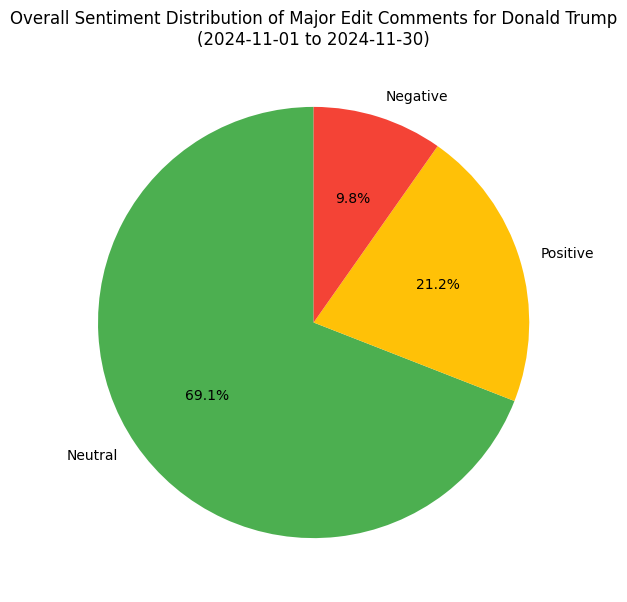

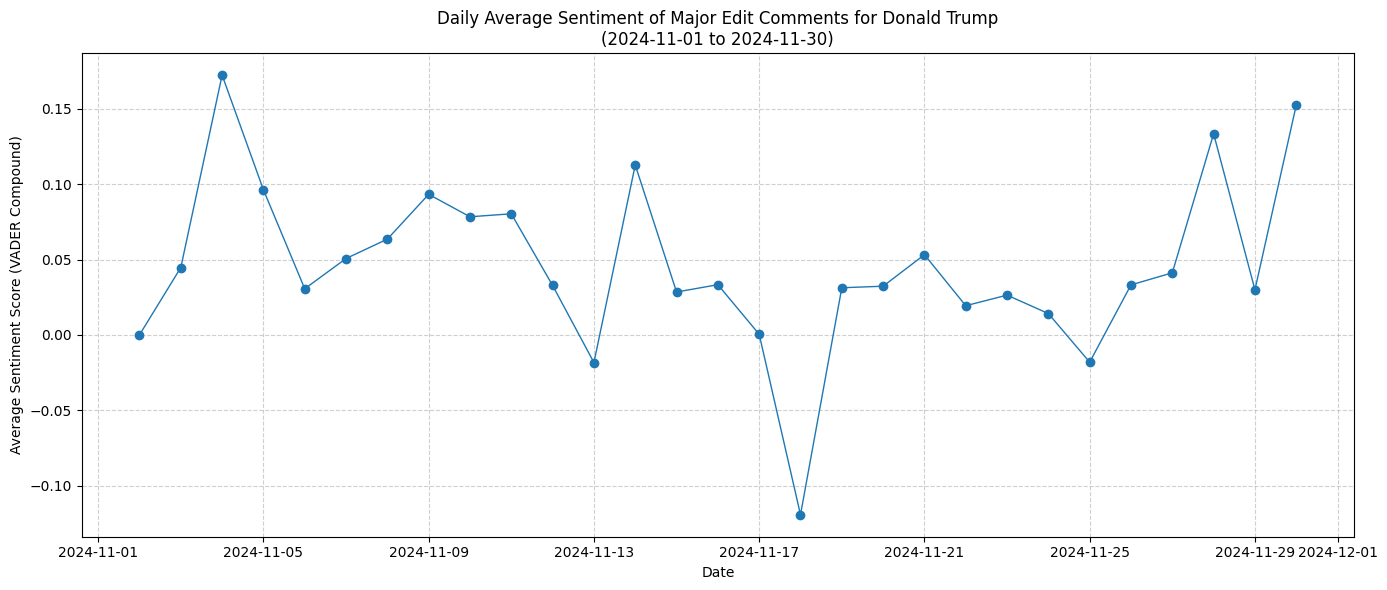



Artemis II (Period: 2026-04-01 to 2026-05-01)

--- Sentiment Analysis for: Artemis II (Major Edits Only) ---


,timestamp,comment,processed_comment,sentiment_score,sentiment_label
0,2026-04-01 00:08:40+00:00,Fixed up link.,fixed link,0.0000,Neutral
1,2026-04-01 02:49:27+00:00,remove image only inserted for asthetic reason...,remove image inserted asthetic reason date rel...,0.0000,Neutral
3,2026-04-01 05:56:47+00:00,/* top */add date range to short description,add date range short description,0.0000,Neutral
4,2026-04-01 13:19:42+00:00,punctuation..,punctuation,0.0000,Neutral
5,2026-04-01 13:58:11+00:00,/* External links */Added a website courtesy a...,added website courtesy reference link encyclop...,0.3612,Positive


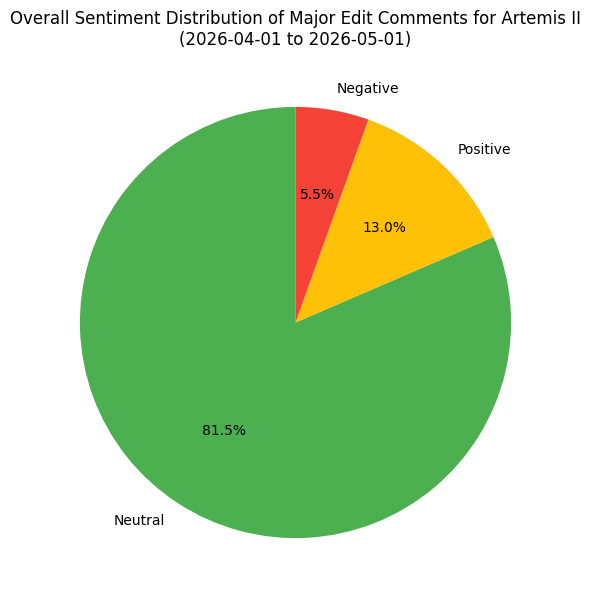

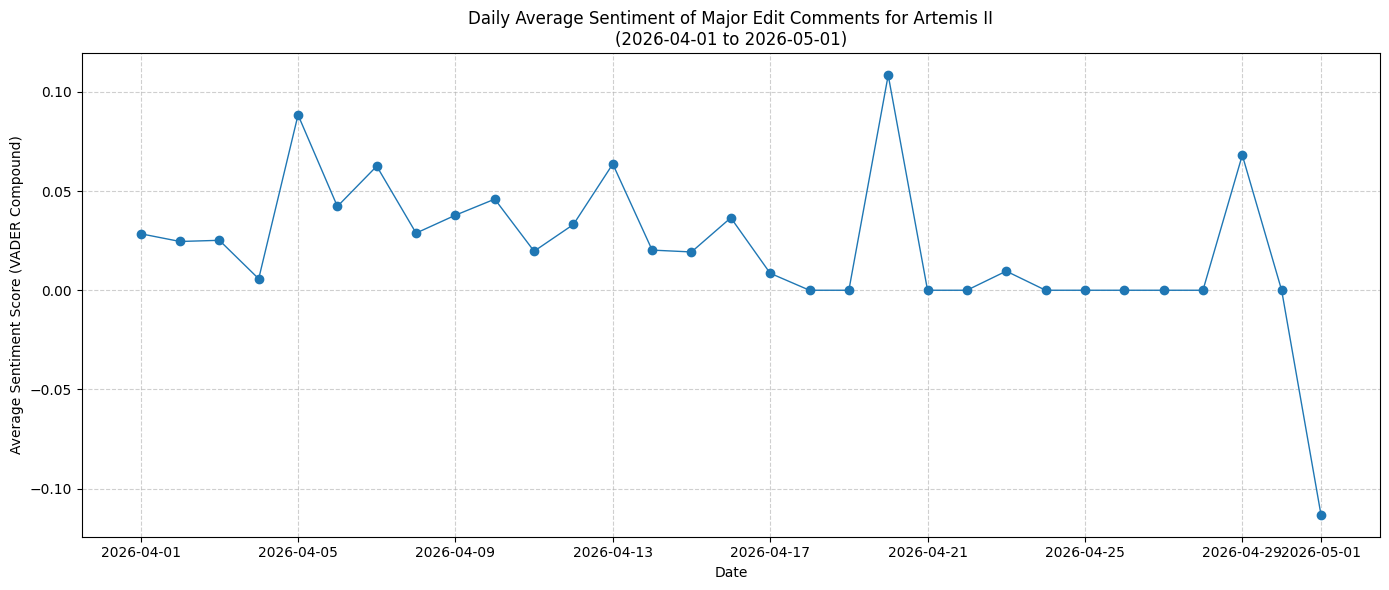



2026 Iran war (Period: 2026-03-13 to Full History)

--- Sentiment Analysis for: 2026 Iran war (Major Edits Only) ---


,timestamp,comment,processed_comment,sentiment_score,sentiment_label
0,2026-03-13 00:12:31+00:00,/* Attacks by ballistic missiles and drones/UA...,comma,0.0,Neutral
3,2026-03-13 00:14:27+00:00,linked,linked,0.0,Neutral
4,2026-03-13 00:25:18+00:00,Undid revision [[Special:Diff/1343213263|13432...,undid revision 1343213263 wamalotpark talk,0.0,Neutral
5,2026-03-13 00:33:09+00:00,/* 12 March */ Altered website.,altered website,0.0,Neutral
6,2026-03-13 00:36:11+00:00,/* International */ Removed reference names.,removed reference name,0.0,Neutral


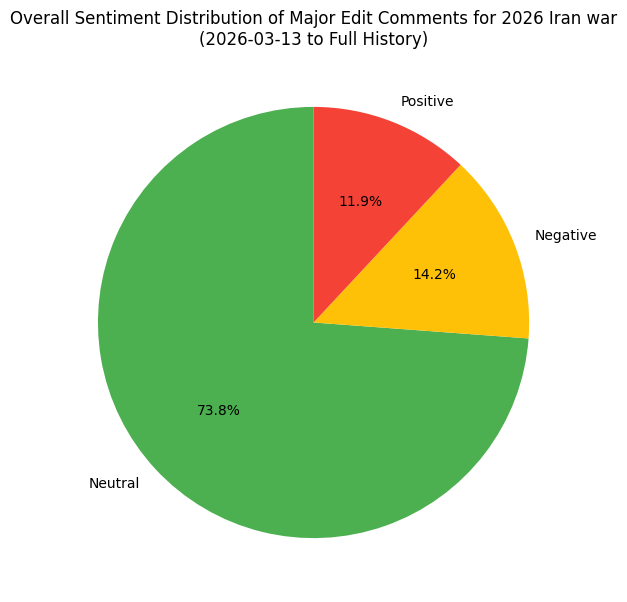

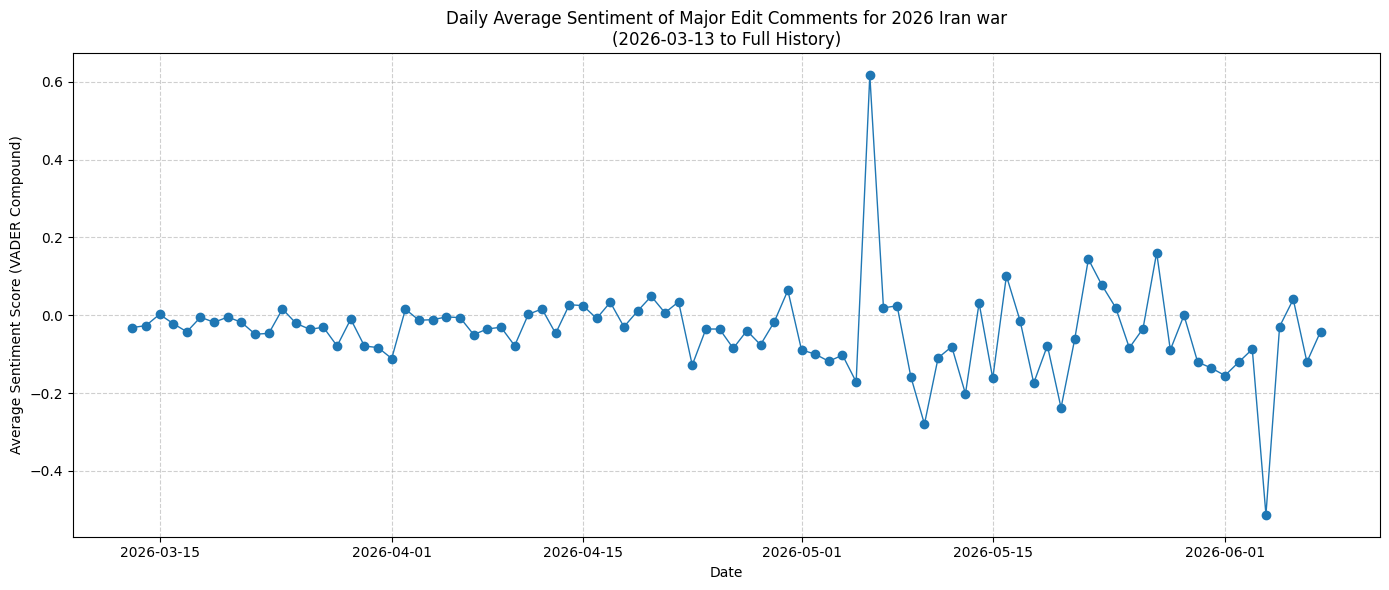



Joe Biden (Period: 2008-08-01 to 2008-06-31)

No data found for Joe Biden for the period 2008-08-01 to 2008-06-31.


Hantavirus (Period: 2026-05-01 to 2026-05-31)

--- Sentiment Analysis for: Hantavirus (Major Edits Only) ---


,timestamp,comment,processed_comment,sentiment_score,sentiment_label
0,2026-05-03 23:43:46+00:00,/* Transmission */ The point after the comma s...,point comma seems 2024 study,0.0000,Neutral
1,2026-05-03 23:46:46+00:00,Remove statement that is more definitive that ...,remove statement definitive presented tortosa ...,0.0000,Neutral
3,2026-05-04 07:44:24+00:00,/* Transmission */ Removing uncited and entire...,removing uncited entirely absurd claim,0.0000,Neutral
4,2026-05-04 07:48:59+00:00,Very explicitly supported by cited source for ...,explicitly supported cited source section para...,0.5267,Positive
7,2026-05-04 17:05:04+00:00,,,0.0000,Neutral


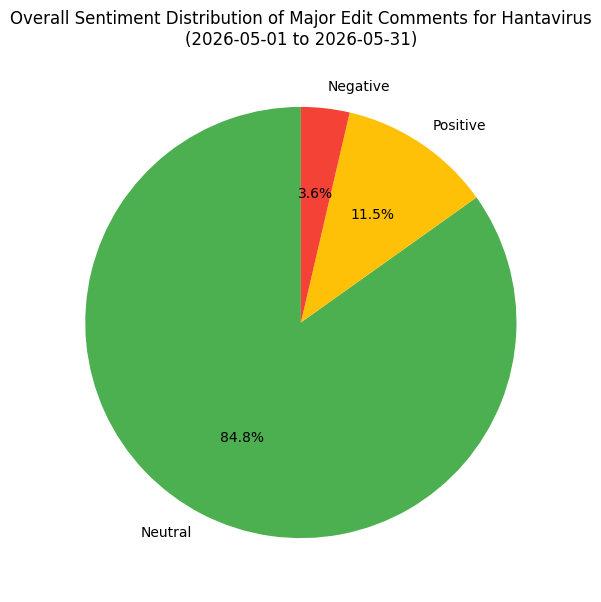

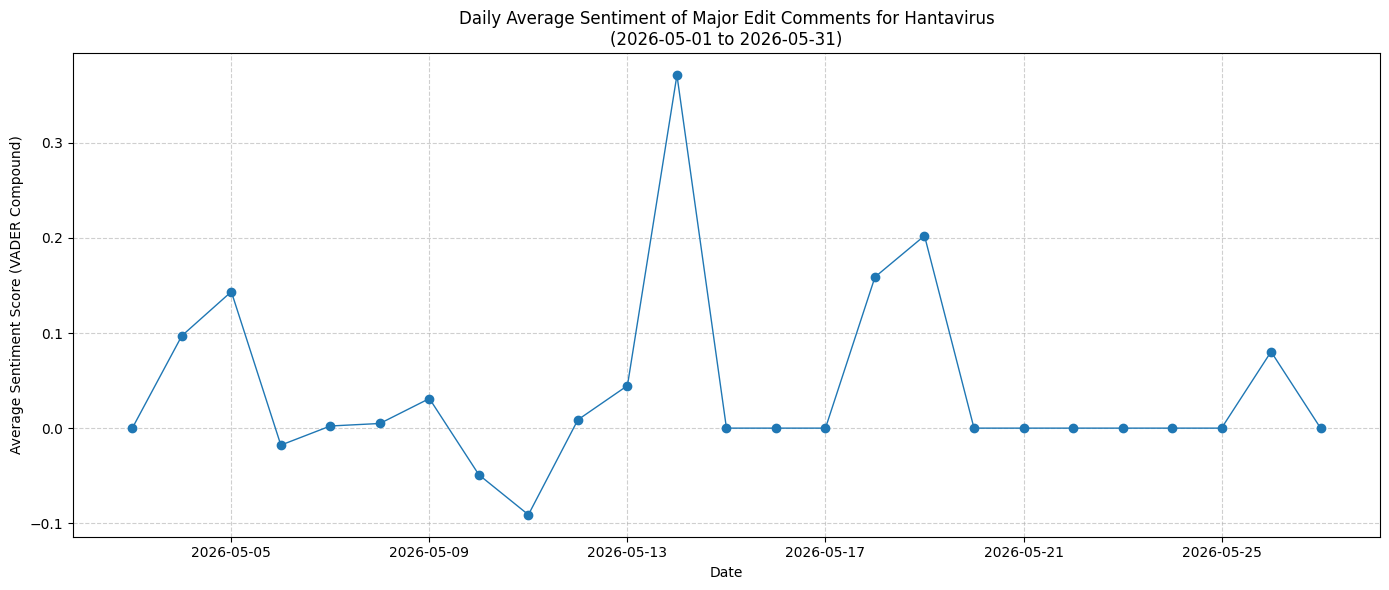



2026 in film (Period: 2016-04-01 to 2016-04-30)

No data found for 2026 in film for the period 2016-04-01 to 2016-04-30.


2026 Lebanon war (Period: 2026-03-01 to 2026-03-30)

--- Sentiment Analysis for: 2026 Lebanon war (Major Edits Only) ---


,timestamp,comment,processed_comment,sentiment_score,sentiment_label
0,2026-03-02 03:17:17+00:00,[[WP:AES|←]]Created page with '{{Current|date=...,created page current date subst currentmonthna...,-0.5994,Negative
1,2026-03-02 03:27:55+00:00,adding,adding,0.0000,Neutral
2,2026-03-02 03:30:41+00:00,adding,adding,0.0000,Neutral
3,2026-03-02 03:36:09+00:00,adding,adding,0.0000,Neutral
4,2026-03-02 03:43:34+00:00,Removing incomprehensible author name hodgepodges,removing incomprehensible author name hodgepodge,0.0000,Neutral


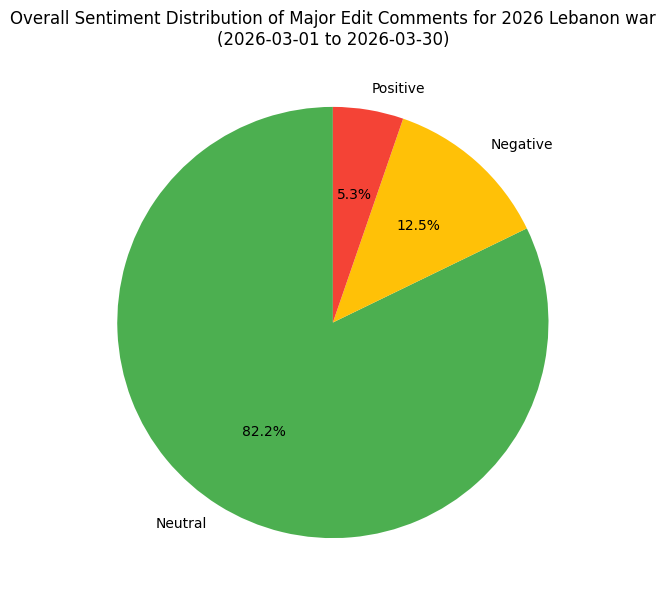

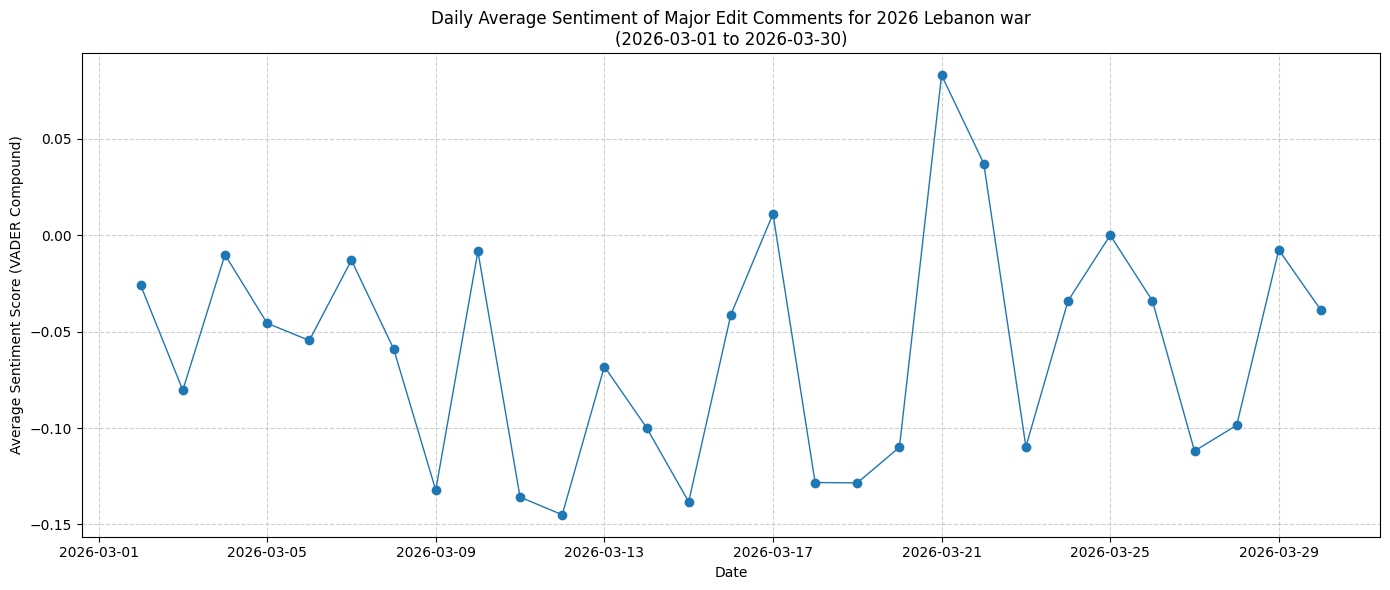



2026 in science (Period: 2026-02-01 to 2026-02-30)

--- Sentiment Analysis for: 2026 in science (Major Edits Only) ---


,timestamp,comment,processed_comment,sentiment_score,sentiment_label
0,2026-02-03 17:04:23+00:00,Removed a bullet point which stated that Alpha...,removed bullet point stated alphagenome unveil...,0.128,Positive
1,2026-02-07 12:12:22+00:00,6 February event,6 february event,0.000,Neutral
2,2026-02-07 13:40:19+00:00,/* February */,,0.000,Neutral
3,2026-02-07 13:51:39+00:00,"/* January */ Restored entry, but reworded to ...",restored entry reworded emphasise new study 28...,0.340,Positive
4,2026-02-07 14:04:08+00:00,23 January event,23 january event,0.000,Neutral


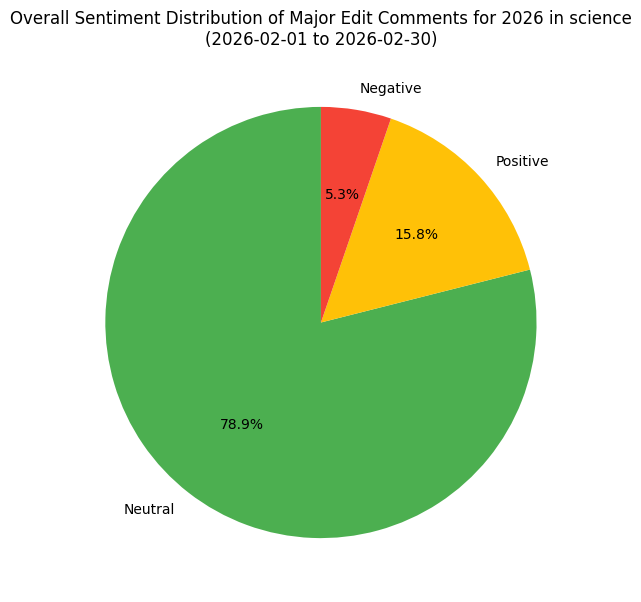

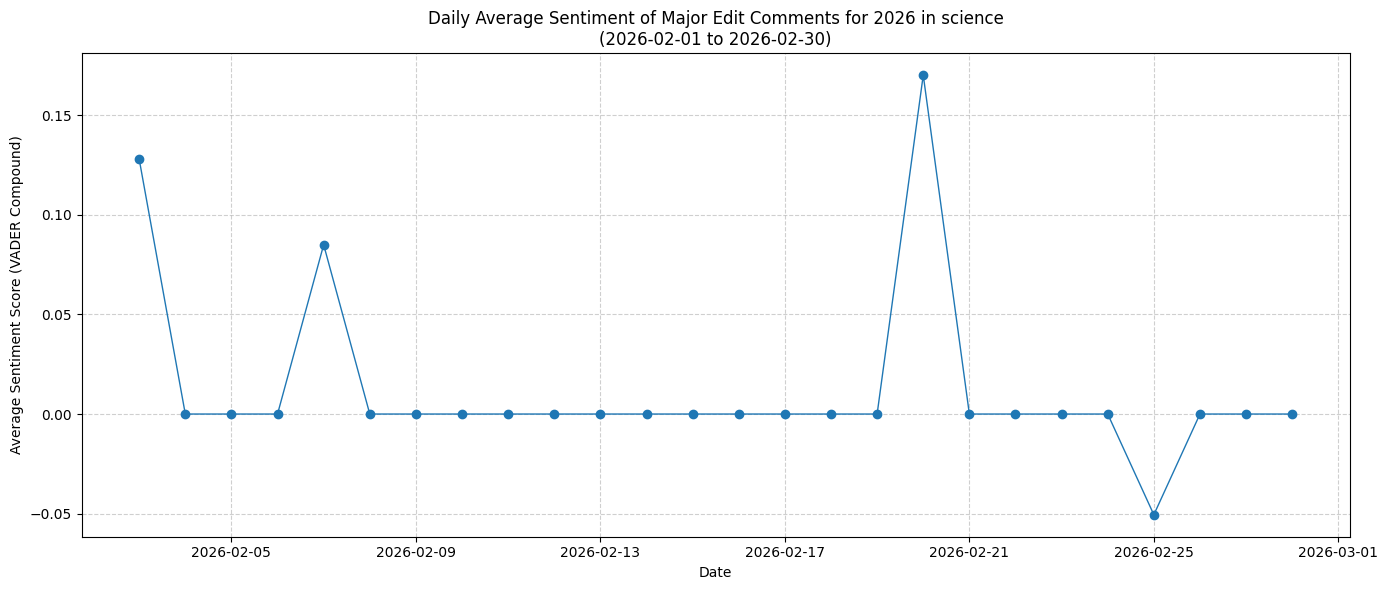

Total major edit comments available for POS tagging and LDA: 6611


,timestamp,comment,category,minor,processed_comment,is_minor,sentiment_score,sentiment_label,commenthidden
0,2024-11-02 15:27:31+00:00,Rmv Wikilink to general article on impeachmen...,Donald Trump,NaN,rmv wikilink general article impeachment numer...,0,0.0,Neutral,NaN
1,2024-11-02 15:30:57+00:00,Rmv Wikilinks not covered by [[Talk:Donald_Tru...,Donald Trump,NaN,rmv wikilinks covered talk consensus 60,0,0.0,Neutral,NaN
2,2024-11-03 09:03:16+00:00,/* top */,Donald Trump,NaN,,0,0.0,Neutral,NaN
3,2024-11-03 09:42:02+00:00,Add relevant template and move two images to a...,Donald Trump,NaN,add relevant template move two image appropria...,0,0.0,Neutral,NaN
4,2024-11-03 12:14:30+00:00,Undid revision [[Special:Diff/1255136113|12551...,Donald Trump,NaN,undid revision 1255136113 biohistorian15 talk ...,0,0.0,Neutral,NaN


In [9]:
# Loop through the configuration and perform VADER analysis for each topic
# Save all major edit comments so POS tagging and LDA can use the same VADER-scored data

vader_results = []

for config in topics_config:
    topic_df = perform_vader(
        config["title"],
        start_date=config["start"],
        end_date=config["end"]
    )

    vader_results.append(topic_df)

all_major_edits_only_df = pd.concat(vader_results, ignore_index=True)

print("Total major edit comments available for POS tagging and LDA:", len(all_major_edits_only_df))
display(all_major_edits_only_df.head())

**POS Tagging**

In [10]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('stopwords')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

from collections import Counter

def get_pos_tags(text):
    tokens = nltk.word_tokenize(str(text))
    tagged_text = nltk.pos_tag(tokens)
    return tagged_text


def get_words_by_pos(pos_tags, tag_prefixes):
    words = []
    for word, tag in pos_tags:
        if any(tag.startswith(prefix) for prefix in tag_prefixes):
            words.append(word)
    return words


# Add POS tags to the same dataframe that already has VADER sentiment
all_major_edits_only_df['pos_tags'] = all_major_edits_only_df['processed_comment'].apply(get_pos_tags)

# Extract word types we care about
all_major_edits_only_df['adjectives'] = all_major_edits_only_df['pos_tags'].apply(lambda tags: get_words_by_pos(tags, ['JJ']))
all_major_edits_only_df['nouns'] = all_major_edits_only_df['pos_tags'].apply(lambda tags: get_words_by_pos(tags, ['NN']))
all_major_edits_only_df['verbs'] = all_major_edits_only_df['pos_tags'].apply(lambda tags: get_words_by_pos(tags, ['VB']))

# Quick check
display(all_major_edits_only_df.head())

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


,timestamp,comment,category,minor,processed_comment,is_minor,sentiment_score,sentiment_label,commenthidden,pos_tags,adjectives,nouns,verbs
0,2024-11-02 15:27:31+00:00,Rmv Wikilink to general article on impeachmen...,Donald Trump,NaN,rmv wikilink general article impeachment numer...,0,0.0,Neutral,NaN,"[(rmv, NN), (wikilink, NN), (general, JJ), (ar...","[general, numerous, talk, current, general, nu...","[rmv, wikilink, article, impeachment, country,...","[see, link]"
1,2024-11-02 15:30:57+00:00,Rmv Wikilinks not covered by [[Talk:Donald_Tru...,Donald Trump,NaN,rmv wikilinks covered talk consensus 60,0,0.0,Neutral,NaN,"[(rmv, NN), (wikilinks, NNS), (covered, VBD), ...",[],"[rmv, wikilinks, talk, consensus]",[covered]
2,2024-11-03 09:03:16+00:00,/* top */,Donald Trump,NaN,,0,0.0,Neutral,NaN,[],[],[],[]
3,2024-11-03 09:42:02+00:00,Add relevant template and move two images to a...,Donald Trump,NaN,add relevant template move two image appropria...,0,0.0,Neutral,NaN,"[(add, VB), (relevant, JJ), (template, JJ), (m...","[relevant, template, appropriate]","[move, image, place, accommodate]",[add]
4,2024-11-03 12:14:30+00:00,Undid revision [[Special:Diff/1255136113|12551...,Donald Trump,NaN,undid revision 1255136113 biohistorian15 talk ...,0,0.0,Neutral,NaN,"[(undid, JJ), (revision, NN), (1255136113, CD)...","[undid, second, tenth, trump, big]","[revision, biohistorian15, talk, conservatism,...","[come, talking]"


In [11]:
# Top adjectives, nouns, and verbs by VADER sentiment label
sentiment_data = {}

for label in ['Negative', 'Neutral', 'Positive']:
    subset = all_major_edits_only_df[all_major_edits_only_df['sentiment_label'] == label]

    adjectives = []
    nouns = []
    verbs = []

    for words in subset['adjectives']:
        adjectives.extend(words)
    for words in subset['verbs']:
        verbs.extend(words)

    # Get top 20 words for each part of speech
    top_adjectives = Counter(adjectives).most_common(20)
    top_nouns = Counter(nouns).most_common(20)
    top_verbs = Counter(verbs).most_common(20)

    # Combine all words into a single frequency dictionary
    combined_words = dict(top_adjectives + top_nouns + top_verbs)
    sentiment_data[label] = combined_words

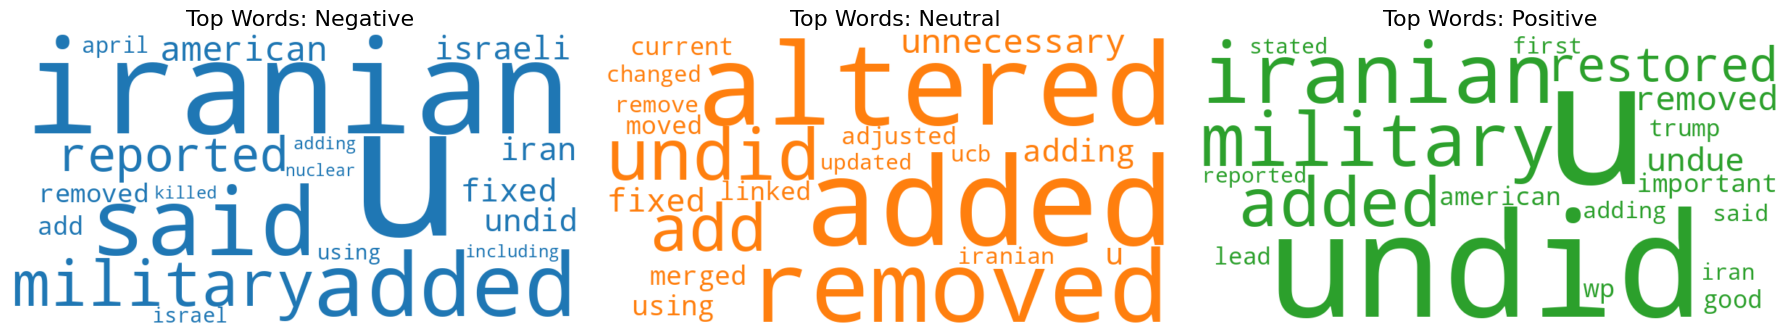

In [12]:
from matplotlib import pyplot as plt
from wordcloud import WordCloud
import matplotlib.colors as mcolors

# Define colors for each sentiment
cols = [color for name, color in mcolors.TABLEAU_COLORS.items()]

# Create a figure with subplots for each sentiment
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

# Generate word clouds for each sentiment
for i, (label, words) in enumerate(sentiment_data.items()):
    cloud = WordCloud(
        background_color='white',
        width=800,
        height=400,
        max_words=20,
        colormap='tab10',
        color_func=lambda *args, **kwargs: cols[i],
        prefer_horizontal=1.0
    ).generate_from_frequencies(words)

    axes[i].imshow(cloud, interpolation='bilinear')
    axes[i].set_title(f'Top Words: {label}', fontdict=dict(size=16))
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# LDA Topic Modeling for Edit Comments
When we see areas of high negativity or edit rates use this to determine what is being argued about or what is being determined

In [13]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 45.9 MB/s eta 0:00:00


In [14]:
# Tokenize and lemmatize text
def normalize_text(doc):
    stop = set(stopwords.words('english'))
    exclude = set(string.punctuation)
    lemma = WordNetLemmatizer()

    # convert text into lower case + split into words + remove stop words
    stop_free = ' '.join([i for i in str(doc).lower().split() if i not in stop])

    # Remove punctuation
    punc_free = ''.join(ch for ch in stop_free if ch not in exclude)

    # Remove digits
    out_string = ''.join(i for i in punc_free if not i.isdigit())

    # lemmatize words
    normalized = ' '.join(lemma.lemmatize(word) for word in out_string.split())

    return normalized

In [15]:
# Import Gensim, following the topic modeling notebook
import gensim
from gensim import corpora
import string

# Use only non-empty processed comments for LDA.
lda_input_df = all_major_edits_only_df[all_major_edits_only_df['processed_comment'].str.strip() != ''].copy()

# Clean comments using the topic-modeling style clean function.
lda_input_df['normalized_comment'] = lda_input_df['processed_comment'].apply(normalize_text)
lda_input_df = lda_input_df[lda_input_df['normalized_comment'].str.strip() != ''].copy()

corpus_1 = lda_input_df['normalized_comment'].tolist()
clean_corpus = [doc.split() for doc in corpus_1]

# Create the term dictionary of our corpus.
dict_ = corpora.Dictionary(clean_corpus)
print(dict_)

# Convert list of documents into Document Term Matrix using the dictionary
doc_term_matrix = [dict_.doc2bow(i) for i in clean_corpus]

# Create the object for LDA model using gensim library
Lda = gensim.models.ldamodel.LdaModel

# Run and train LDA model on the document term matrix
num_topics = 3
ldamodel = Lda(doc_term_matrix, num_topics=num_topics, id2word=dict_, passes=10, random_state=0, iterations=50, eval_every=None)

# Print topics with their top words.
print(ldamodel.print_topics(num_topics=num_topics, num_words=10))

Dictionary<4309 unique tokens: ['also', 'article', 'consensus', 'country', 'current']...>
[(0, '0.022*"talk" + 0.022*"iran" + 0.013*"trump" + 0.013*"revision" + 0.011*"undid" + 0.010*"u" + 0.010*"per" + 0.009*"may" + 0.008*"mo" + 0.008*"sentence"'), (1, '0.025*"added" + 0.021*"source" + 0.018*"article" + 0.015*"date" + 0.015*"israel" + 0.015*"wp" + 0.015*"iran" + 0.013*"removed" + 0.012*"war" + 0.012*"updated"'), (2, '0.024*"reference" + 0.022*"added" + 0.022*"altered" + 0.021*"name" + 0.020*"iran" + 0.019*"u" + 0.016*"iranian" + 0.014*"website" + 0.013*"may" + 0.012*"trump"')]


In [16]:
# Create a matrix of the most probable topic for each edit comment
# This follows the format_topics_sentences function from the topic modeling notebook

def format_topics_sentences(ldamodel=None, corpus=doc_term_matrix, texts=corpus_1):
    rows = []

    # Get main topic in each document
    for i, row_list in enumerate(ldamodel[corpus]):
        row = row_list[0] if ldamodel.per_word_topics else row_list
        row = sorted(row, key=lambda x: x[1], reverse=True)

        # Get dominant topic, contribution, and keywords
        for j, (topic_num, prop_topic) in enumerate(row):
            if j == 0:
                wp = ldamodel.show_topic(topic_num)
                topic_keywords = ", ".join([word for word, prop in wp])
                rows.append([int(topic_num), round(prop_topic, 4), topic_keywords])
            else:
                break

    sent_topics_df = pd.DataFrame(rows, columns=['Dominant_Topic', 'Topic_Perc_Contrib', 'Keywords'])

    contents = pd.Series(texts, name='Text')
    sent_topics_df = pd.concat([sent_topics_df, contents], axis=1)

    return sent_topics_df


df_topic_sents_keywords = format_topics_sentences(
    ldamodel=ldamodel,
    corpus=doc_term_matrix,
    texts=corpus_1
)

# Add the dominant LDA topic back to the original edit-comment dataframe
lda_results_df = lda_input_df.reset_index(drop=True).copy()
lda_results_df = pd.concat(
    [lda_results_df, df_topic_sents_keywords[['Dominant_Topic', 'Topic_Perc_Contrib', 'Keywords']]],
    axis=1
)

display(lda_results_df.head(20))

,timestamp,comment,category,minor,processed_comment,is_minor,sentiment_score,sentiment_label,commenthidden,pos_tags,adjectives,nouns,verbs,normalized_comment,Dominant_Topic,Topic_Perc_Contrib,Keywords
0,2024-11-02 15:27:31+00:00,Rmv Wikilink to general article on impeachmen...,Donald Trump,NaN,rmv wikilink general article impeachment numer...,0,0.0000,Neutral,NaN,"[(rmv, NN), (wikilink, NN), (general, JJ), (ar...","[general, numerous, talk, current, general, nu...","[rmv, wikilink, article, impeachment, country,...","[see, link]",rmv wikilink general article impeachment numer...,0,0.4948,"talk, iran, trump, revision, undid, u, per, ma..."
1,2024-11-02 15:30:57+00:00,Rmv Wikilinks not covered by [[Talk:Donald_Tru...,Donald Trump,NaN,rmv wikilinks covered talk consensus 60,0,0.0000,Neutral,NaN,"[(rmv, NN), (wikilinks, NNS), (covered, VBD), ...",[],"[rmv, wikilinks, talk, consensus]",[covered],rmv wikilinks covered talk consensus,0,0.8880,"talk, iran, trump, revision, undid, u, per, ma..."
2,2024-11-03 09:42:02+00:00,Add relevant template and move two images to a...,Donald Trump,NaN,add relevant template move two image appropria...,0,0.0000,Neutral,NaN,"[(add, VB), (relevant, JJ), (template, JJ), (m...","[relevant, template, appropriate]","[move, image, place, accommodate]",[add],add relevant template move two image appropria...,1,0.9232,"added, source, article, date, israel, wp, iran..."
3,2024-11-03 12:14:30+00:00,Undid revision [[Special:Diff/1255136113|12551...,Donald Trump,NaN,undid revision 1255136113 biohistorian15 talk ...,0,0.0000,Neutral,NaN,"[(undid, JJ), (revision, NN), (1255136113, CD)...","[undid, second, tenth, trump, big]","[revision, biohistorian15, talk, conservatism,...","[come, talking]",undid revision biohistorian talk conservatism ...,0,0.7914,"talk, iran, trump, revision, undid, u, per, ma..."
4,2024-11-03 12:51:53+00:00,/* Early life */ Editing per [[Talk:Donald_Tru...,Donald Trump,NaN,editing per talk donald trumpwording sentence ...,0,0.0772,Positive,NaN,"[(editing, VBG), (per, IN), (talk, NN), (donal...","[new, military]","[talk, donald, sentence, trump, york, academy,...","[editing, trumpwording, attending]",editing per talk donald trumpwording sentence ...,0,0.9513,"talk, iran, trump, revision, undid, u, per, ma..."
5,2024-11-03 13:26:03+00:00,/* 2024 presidential campaign */ Adding about...,Donald Trump,NaN,adding estimation effect trump considering env...,0,0.0000,Neutral,NaN,"[(adding, VBG), (estimation, NN), (effect, NN)...",[],"[estimation, effect, trump, environment, duron...","[adding, considering]",adding estimation effect trump considering env...,0,0.8356,"talk, iran, trump, revision, undid, u, per, ma..."
6,2024-11-03 13:29:03+00:00,Undid revision [[Special:Diff/1255160116|12551...,Donald Trump,NaN,undid revision 1255160116 talk wildly speculat...,0,0.4588,Positive,NaN,"[(undid, JJ), (revision, NN), (1255160116, CD)...","[undid, speculative, clear, prose, undue]","[revision, talk, article, outcome, guaranteed,...",[added],undid revision talk wildly speculative article...,0,0.8030,"talk, iran, trump, revision, undid, u, per, ma..."
7,2024-11-03 15:05:22+00:00,{{Pronunciation needed}} template added,Donald Trump,NaN,pronunciation needed template added,0,0.0000,Neutral,NaN,"[(pronunciation, NN), (needed, VBN), (template...",[],"[pronunciation, template]","[needed, added]",pronunciation needed template added,2,0.8575,"reference, added, altered, name, iran, u, iran..."
8,2024-11-03 16:31:04+00:00,Undid revision [[Special:Diff/1255132088|12551...,Donald Trump,NaN,undid revision 1255132088 anand michael v talk...,0,0.0000,Neutral,NaN,"[(undid, JJ), (revision, NN), (1255132088, CD)...",[undid],"[revision, anand, michael, v, talk, word, need...","[capitalized, template]",undid revision anand michael v talk first word...,0,0.7085,"talk, iran, trump, revision, undid, u, per, ma..."
9,2024-11-03 16:42:44+00:00,Undid revision [[Special:Diff/1255174483|12551...,Donald Trump,NaN,undid revision 1255174483 n

In [17]:
!pip install pyLDAvis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 6.5 MB/s eta 0:00:00


In [18]:
# Visualize the LDA model
import pyLDAvis
import pyLDAvis.gensim_models

pyLDAvis.enable_notebook()

vis = pyLDAvis.gensim_models.prepare(ldamodel, doc_term_matrix, dictionary=ldamodel.id2word)

vis

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0     -0.081786 -0.183159       1        1  37.948553
1     -0.125705  0.159017       2        1  33.559066
2      0.207491  0.024142       3        1  28.492381, topic_info=           Term        Freq       Total Category  logprob  loglift
417   reference  200.000000  200.000000  Default  30.0000  30.0000
11         talk  235.000000  235.000000  Default  29.0000  29.0000
360     altered  176.000000  176.000000  Default  28.0000  28.0000
78         name  171.000000  171.000000  Default  27.0000  27.0000
56        added  415.000000  415.000000  Default  26.0000  26.0000
...         ...         ...         ...      ...      ...      ...
324     removed   56.386270  176.789112   Topic3  -4.9740   0.1128
43     military   49.302707  153.467301   Topic3  -5.1082   0.1200
1767   official   38.598467   71.033540   Topic3  -5.3530   0.6456
2551     strike   43.348884  125.181979   Topic3  -5.2369   0.1950
2432        war   40.805832  205.731306   Topic3  -5.2974  -0.3622

[192 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
16        1  0.072741         add
16        2  0.921392         add
56        2  0.568527       added
56        3  0.431213       added
1558      2  0.984283  additional
...     ...       ...         ...
12        2  0.958425    wikilink
332       3  0.995021        work
115       1  0.879519       would
115       3  0.109940       would
325       2  0.996267          wp

[229 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3])

In [19]:
# Rank LDA topics by VADER sentiment.
# The most negative average VADER score is the likely raid/conflict topic.

topic_sentiment_summary = lda_results_df.groupby('Dominant_Topic').agg(
    edit_count=('processed_comment', 'count'),
    avg_vader_score=('sentiment_score', 'mean'),
    negative_share=('sentiment_label', lambda x: (x == 'Negative').mean() * 100),
    topic_keywords=('Keywords', 'first')
).reset_index()

topic_sentiment_summary = topic_sentiment_summary.sort_values('avg_vader_score')

display(topic_sentiment_summary)

most_negative_topic = topic_sentiment_summary.iloc[0]['Dominant_Topic']
print('Most negative LDA topic based on VADER score:', most_negative_topic)
print('Topic keywords:', topic_sentiment_summary.iloc[0]['topic_keywords'])

,Dominant_Topic,edit_count,avg_vader_score,negative_share,topic_keywords
1,1,1831,-0.037265,18.569088,"added, source, article, date, israel, wp, iran..."
2,2,1614,-0.014262,13.011152,"reference, added, altered, name, iran, u, iran..."
0,0,1528,0.032861,14.725131,"talk, iran, trump, revision, undid, u, per, ma..."


Most negative LDA topic based on VADER score: 1
Topic keywords: added, source, article, date, israel, wp, iran, removed, war, updated


In [20]:
# Show sample comments from the most negative topic.
# Read these comments to decide whether the most negative topic is actually the raid/conflict topic.

most_negative_topic_comments = lda_results_df[
    lda_results_df['Dominant_Topic'] == most_negative_topic
].sort_values('sentiment_score')

display(most_negative_topic_comments.head(20))

,timestamp,comment,category,minor,processed_comment,is_minor,sentiment_score,sentiment_label,commenthidden,pos_tags,adjectives,nouns,verbs,normalized_comment,Dominant_Topic,Topic_Perc_Contrib,Keywords
2311,2026-03-18 13:50:28+00:00,copyedit and/or wikify; add / update ref(s) re...,2026 Iran war,NaN,copyedit wikify add update ref death two israe...,0,-0.9531,Negative,NaN,"[(copyedit, NN), (wikify, WRB), (add, NN), (up...","[update, ref, israeli, civilian, ali]","[copyedit, add, death, cluster, munition, irgc...","[calling, killed, killing]",copyedit wikify add update ref death two israe...,1,0.9649,"added, source, article, date, israel, wp, iran..."
1011,2024-11-25 18:46:41+00:00,Trumpism isn't mentioned in [[#2016 presidenti...,Donald Trump,NaN,trumpism mentioned 2016 presidential election ...,0,-0.9468,Negative,NaN,"[(trumpism, NN), (mentioned, VBD), (2016, CD),...","[presidential, political, trump, rhetoric, rac...","[trumpism, election, practice, rhetoric, polit...","[mentioned, mentioned, say, led, includes, men...",trumpism mentioned presidential election menti...,1,0.8931,"added, source, article, date, israel, wp, iran..."
4824,2026-03-11 11:21:09+00:00,Hezbollah later claimed that the attack was a ...,2026 Lebanon war,NaN,hezbollah later claimed attack defensive act y...,0,-0.9423,Negative,NaN,"[(hezbollah, NN), (later, RB), (claimed, VBD),...","[defensive, israeli, stop, lebanese, unrelated]","[hezbollah, act, year, attack, truce, force, i...","[claimed, added, restarted, fighting, seized, ...",hezbollah later claimed attack defensive act y...,1,0.9739,"added, source, article, date, israel, wp, iran..."
4823,2026-03-11 11:12:39+00:00,Hezbollah later claimed that the attack was a ...,2026 Lebanon war,NaN,hezbollah later claimed attack defensive act y...,0,-0.9423,Negative,NaN,"[(hezbollah, NN), (later, RB), (claimed, VBD),...","[defensive, israeli, stop, lebanese, unrelated]","[hezbollah, act, year, attack, truce, force, i...","[claimed, added, restarted, fighting, seized, ...",hezbollah later claimed attack defensive act y...,1,0.9739,"added, source, article, date, israel, wp, iran..."
3301,2026-04-09 15:07:50+00:00,Add information about deception operation lead...,2026 Iran war,NaN,add information deception operation leading op...,0,-0.9042,Negative,NaN,"[(add, VB), (information, NN), (deception, NN)...","[strike, unusual]","[information, deception, operation, war, opera...","[add, leading, opening, enabled, written, expl...",add information deception operation leading op...,1,0.6987,"added, source, article, date, israel, wp, iran..."
2491,2026-03-21 17:27:44+00:00,This doesn't really belong in this article (no...,2026 Iran war,NaN,really belong article section hostility alread...,0,-0.8885,Negative,NaN,"[(really, RB), (belong, JJ), (article, NN), (s...","[belong, covered]","[article, section, hostility, list, aviation, ...",[],really belong article section hostility alread...,1,0.7601,"added, source, article, date, israel, wp, iran..."
4058,2026-05-03 10:25:40+00:00,Restored revision 1352292008 by [[Special:Cont...,2026 Iran war,NaN,restored revision 1352292008 rageking890 talk ...,0,-0.8834,Negative,NaN,"[(restored, VBN), (revision, NN), (1352292008,...",[unnecessary],"[revision, rageking890, talk, cabinet, discuss...",[restored],restored revision rageking talk unnecessary ca...,1,0.5423,"added, source, article, date, israel, wp, iran..."
2755,2026-03-28 05:51:06+00:00,/* Fourth week (21 March – present) */On 27 Ma...,2026 Iran war,NaN,27 march iranian missile drone attack prince s...,0,-0.8779,Negative,NaN,"[(27, CD), (march, NN), (iranian, JJ), (missil...","[iranian, several, u, ten, u, soldier]","[march, missile, drone, attack, prince, sultan...","[damaged, refueling, injured, including]",march iranian missile drone attack prince sult...,1,0.9639,"added, source, article, date, israel, wp, iran..."
2758,2026-03-28 06:31:35+00:00,/* Fourth week (21 March – present) */On 27 Ma...,2026 Iran war,NaN,27 march iranian m

In [21]:
# POS words inside the most negative LDA topic.
# This connects POS tagging back to the likely raid/conflict topic.

negative_topic_pos_df = most_negative_topic_comments.copy()
negative_topic_pos_df['pos_tags'] = negative_topic_pos_df['processed_comment'].apply(get_pos_tags)
negative_topic_pos_df['adjectives'] = negative_topic_pos_df['pos_tags'].apply(lambda tags: get_words_by_pos(tags, ['JJ']))
negative_topic_pos_df['nouns'] = negative_topic_pos_df['pos_tags'].apply(lambda tags: get_words_by_pos(tags, ['NN']))
negative_topic_pos_df['verbs'] = negative_topic_pos_df['pos_tags'].apply(lambda tags: get_words_by_pos(tags, ['VB']))

negative_topic_adjectives = []
negative_topic_nouns = []
negative_topic_verbs = []

for words in negative_topic_pos_df['adjectives']:
    negative_topic_adjectives.extend(words)
for words in negative_topic_pos_df['nouns']:
    negative_topic_nouns.extend(words)
for words in negative_topic_pos_df['verbs']:
    negative_topic_verbs.extend(words)

print('Top adjectives in the most negative LDA topic:')
print(Counter(negative_topic_adjectives).most_common(20))

print('\nTop nouns in the most negative LDA topic:')
print(Counter(negative_topic_nouns).most_common(20))

print('\nTop verbs in the most negative LDA topic:')
print(Counter(negative_topic_verbs).most_common(20))

Top adjectives in the most negative LDA topic:
[('added', 150), ('u', 87), ('iranian', 58), ('updated', 54), ('undue', 44), ('update', 33), ('wp', 29), ('ucb', 29), ('url', 23), ('bot', 22), ('military', 18), ('iran', 18), ('bare', 18), ('ref', 17), ('specific', 17), ('altered', 16), ('israeli', 15), ('additional', 15), ('fix', 15), ('due', 14)]

Top nouns in the most negative LDA topic:
[('date', 183), ('article', 162), ('source', 159), ('wp', 114), ('iran', 95), ('war', 94), ('ref', 88), ('citation', 69), ('parameter', 63), ('update', 62), ('section', 60), ('strike', 57), ('fix', 55), ('image', 54), ('category', 49), ('use', 47), ('copyedit', 46), ('israel', 44), ('reference', 40), ('info', 40)]

Top verbs in the most negative LDA topic:
[('added', 123), ('removed', 119), ('add', 86), ('using', 49), ('adding', 38), ('updated', 26), ('moving', 25), ('suggested', 22), ('said', 21), ('remove', 21), ('removing', 19), ('filled', 19), ('duplicated', 18), ('say', 17), ('reported', 17), ('hi

# Raid Keyword Analysis
We wanted to see if we could use words that indicate vandalism to see at what points are comments most likely to indicate vandalism

In [22]:
raid_keywords = ['revert', 'undid', 'rvv', 'vandal', 'hoax', 'fake', 'disinfo', 'false', 'attack']

print("Starting Raid Analysis across configurations...\n" + "="*60)

for item in topics_config:
    # Safe retrieval using .get() to prevent KeyErrors
    topic = item.get("title")
    start = item.get("start")
    end = item.get("end")

    # Fetch the history using your existing get_refined_history function
    data = get_refined_history(topic, start_date=start, end_date=end)

    if not data:
        print(f"Skipping [{topic}] ({start} to {end}): No data returned.")
        print("-"*60)
        continue

    # Convert to DataFrame
    df = pd.DataFrame(data)

    # Ensure the comment column exists and fill missing values with empty strings
    if 'comment' not in df.columns:
        df['comment'] = ""
    df['comment'] = df['comment'].fillna("")

    # Look for the raid keywords in the comments (Case-Insensitive)
    # Using a regex pattern joined by the pipe '|' character (meaning OR)
    pattern = '|'.join(raid_keywords)
    df['is_raid_action'] = df['comment'].str.contains(pattern, case=False, na=False)

    #  Calculate metrics
    total_edits = len(df)
    raid_actions_count = df['is_raid_action'].sum()

    # Prevent division by zero if an article has no edits
    raid_percentage = (raid_actions_count / total_edits * 100) if total_edits > 0 else 0

    # Output Results
    date_label = f"{start} to {end}" if start or end else "Full History"
    print(f"Topic: **{topic}**")
    print(f"Timeframe: {date_label}")
    print(f"Total Edits Fetched: {total_edits}")
    print(f"Raid/Revert Actions Detected: {raid_actions_count} ({raid_percentage:.1f}% of all edits)")

    # Print out a couple of actual raid descriptions found if they exist
    if raid_actions_count > 0:
        print("Sample Raid Cleanup Comments:")
        samples = df[df['is_raid_action'] == True]['comment'].head(3).values
        for sample in samples:
            # Clean up long comments for readability
            short_sample = sample[:80] + '...' if len(sample) > 80 else sample
            print(f"  - \"{short_sample.strip()}\"")

    print("-"*60)

Starting Raid Analysis across configurations...
Topic: **Donald Trump**
Timeframe: 2024-11-01 to 2024-11-30
Total Edits Fetched: 1545
Raid/Revert Actions Detected: 162 (10.5% of all edits)
Sample Raid Cleanup Comments:
  - "Undid revision [[Special:Diff/1255136113|1255136113]] by [[Special:Contributions..."
  - "/* False or misleading statements */ It's a major article"
  - "Undid revision [[Special:Diff/1255160116|1255160116]] by [[Special:Contributions..."
------------------------------------------------------------
Topic: **Artemis II**
Timeframe: 2026-04-01 to 2026-05-01
Total Edits Fetched: 1111
Raid/Revert Actions Detected: 50 (4.5% of all edits)
Sample Raid Cleanup Comments:
  - "Undid revision [[Special:Diff/1346616864|1346616864]] by [[Special:Contributions..."
  - "Reverted [[WP:AGF|good faith]] edits by [[Special:Contributions/Targets|Targets]..."
  - "Undid revision [[Special:Diff/1346625420|1346625420]] by [[Special:Contributions..."
---------------------------------------

In [23]:
raid_keywords = ['rvv', 'vandal', 'hoax', 'fake', 'disinfo', 'false', 'attack']
pattern = '|'.join(raid_keywords)

print("Finding Peak Raid Months Across Topics\n" + "="*65)

for item in topics_config:
    topic = item.get("title")
    start = item.get("start")
    end = item.get("end")

    # Fetch data
    data = get_refined_history(topic, start_date=start, end_date=end)

    if not data:
        print(f"Skipping [{topic}]: No data found.")
        print("-"*65)
        continue

    df = pd.DataFrame(data)
    df['timestamp'] = pd.to_datetime(df['timestamp'])

    # Handle comments cleanly
    if 'comment' not in df.columns:
        df['comment'] = ""
    df['comment'] = df['comment'].fillna("")

    # Tag rows that contain a raid keyword
    df['is_raid'] = df['comment'].str.contains(pattern, case=False, na=False)

    # Extract Year-Month for grouping
    df['year_month'] = df['timestamp'].dt.to_period('M')

    # Aggregate to find the maximum raid month
    # We filter for only the rows where a raid occurred, group by month, and count them
    raid_edits_only = df[df['is_raid'] == True]

    if raid_edits_only.empty:
        print(f"Topic: **{topic}**")
        print("  -> No raid actions detected in this entire dataset window.")
        print("-"*65)
        continue

    # Find the month with the max count of raid actions
    monthly_raid_counts = raid_edits_only.groupby('year_month').size()
    peak_month = monthly_raid_counts.idxmax()
    max_raid_count = monthly_raid_counts.max()

    # Calculate the total edits in that specific month to find the ratio
    total_edits_in_peak_month = df[df['year_month'] == peak_month].shape[0]
    raid_ratio = (max_raid_count / total_edits_in_peak_month) * 100 if total_edits_in_peak_month > 0 else 0

    # Print Summary
    print(f"Topic: **{topic}**")
    print(f"Peak Raid Month: {peak_month}")
    print(f"Raid Actions in Month: {max_raid_count} cleanups")
    print(f" Intensity: {raid_ratio:.1f}% of this month's edits were raid responses.")
    print("-"*65)

Finding Peak Raid Months Across Topics


/tmp/ipykernel_6573/3221410809.py:31: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['year_month'] = df['timestamp'].dt.to_period('M')


Topic: **Donald Trump**
Peak Raid Month: 2024-11
Raid Actions in Month: 23 cleanups
 Intensity: 1.5% of this month's edits were raid responses.
-----------------------------------------------------------------


/tmp/ipykernel_6573/3221410809.py:31: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['year_month'] = df['timestamp'].dt.to_period('M')


Topic: **Artemis II**
Peak Raid Month: 2026-04
Raid Actions in Month: 1 cleanups
 Intensity: 0.1% of this month's edits were raid responses.
-----------------------------------------------------------------


...

/tmp/ipykernel_6573/3221410809.py:31: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['year_month'] = df['timestamp'].dt.to_period('M')


Topic: **Hantavirus**
Peak Raid Month: 2026-05
Raid Actions in Month: 18 cleanups
 Intensity: 7.7% of this month's edits were raid responses.
-----------------------------------------------------------------
Skipping [2026 in film]: No data found.
-----------------------------------------------------------------


/tmp/ipykernel_6573/3221410809.py:31: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['year_month'] = df['timestamp'].dt.to_period('M')


Topic: **2026 Lebanon war**
Peak Raid Month: 2026-03
Raid Actions in Month: 14 cleanups
 Intensity: 2.5% of this month's edits were raid responses.
-----------------------------------------------------------------
Topic: **2026 in science**
  -> No raid actions detected in this entire dataset window.
-----------------------------------------------------------------


/tmp/ipykernel_6573/3221410809.py:31: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['year_month'] = df['timestamp'].dt.to_period('M')


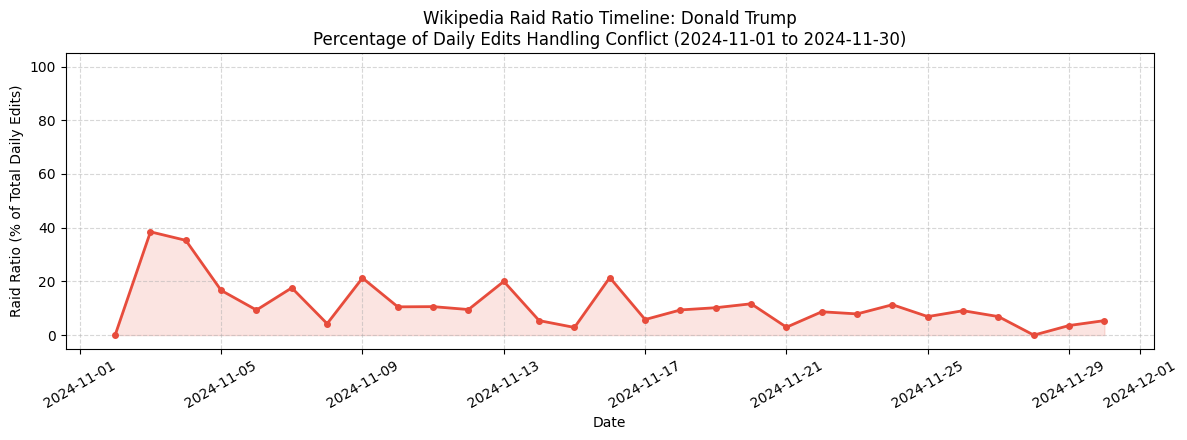

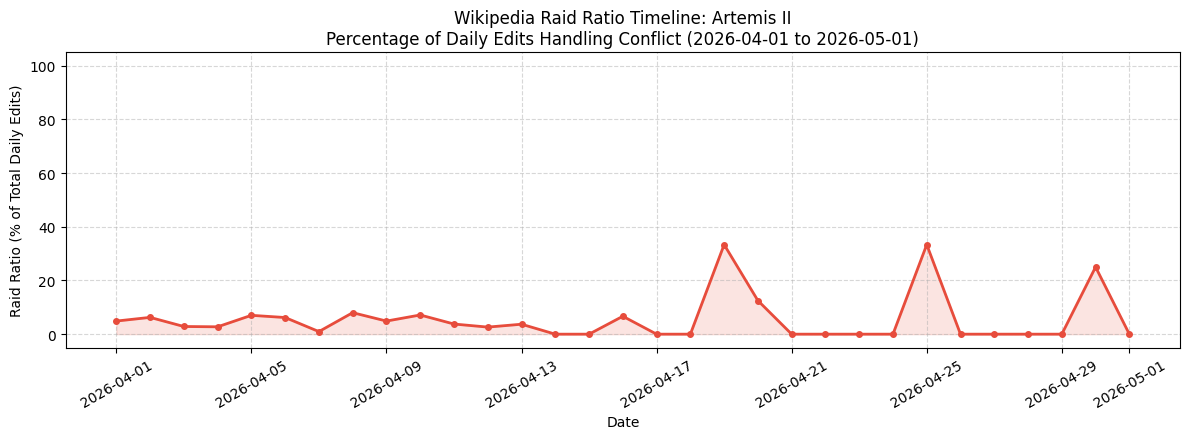

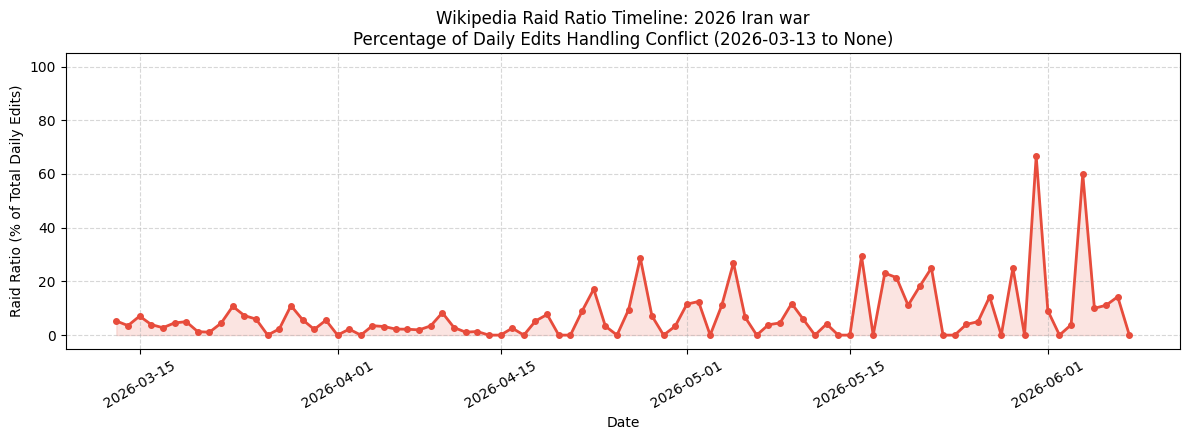

Skipping [Joe Biden]: No data found.


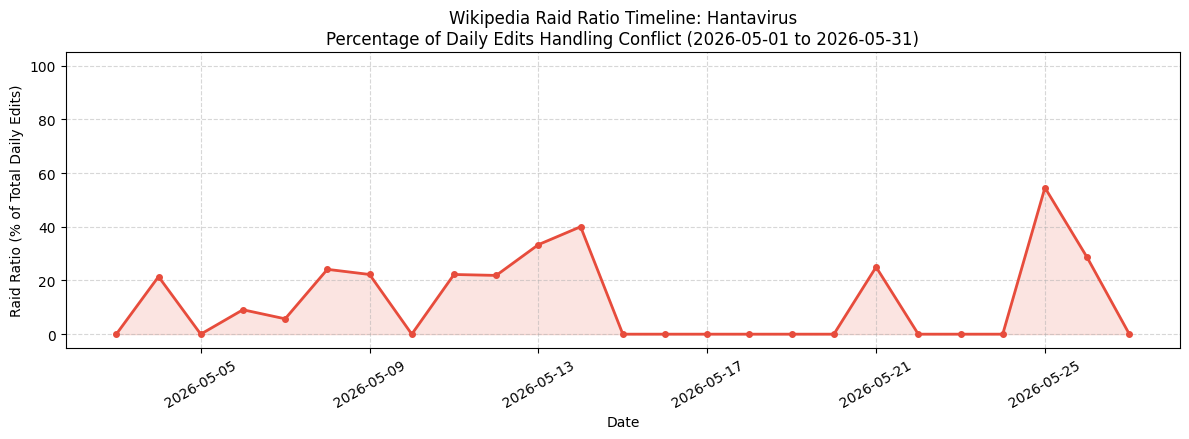

Skipping [2026 in film]: No data found.


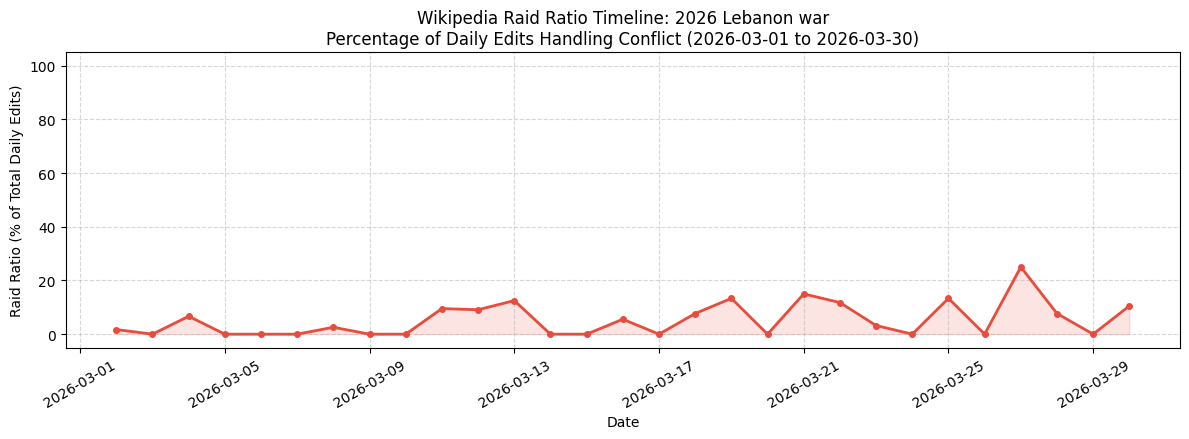

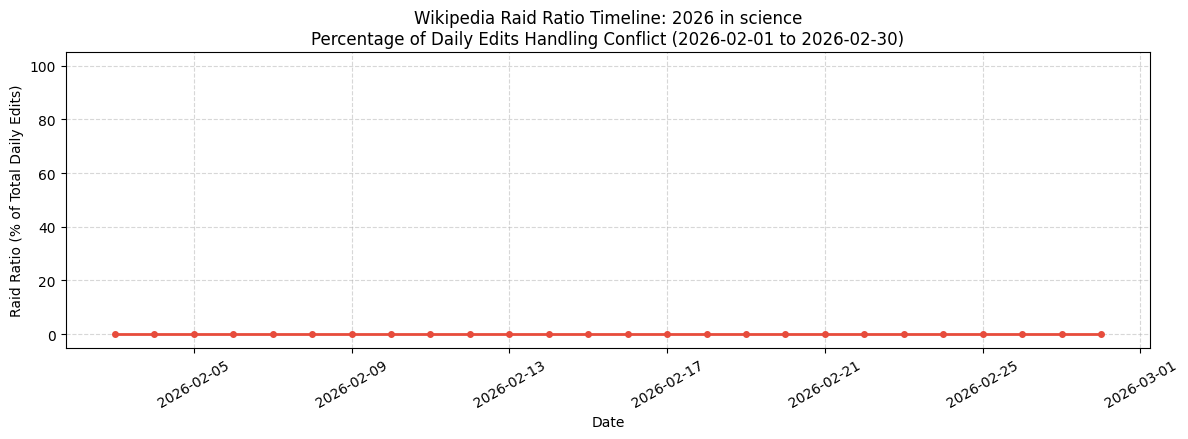

In [24]:
# Standard raid indicators found in Wikipedia edit summaries
raid_keywords = ['revert', 'undid', 'rvv', 'vandal', 'hoax', 'fake', 'disinfo', 'false', 'attack']
pattern = '|'.join(raid_keywords)

for item in topics_config:
    topic = item.get("title")
    start = item.get("start")
    end = item.get("end")

    # Fetch dataset using your function
    data = get_refined_history(topic, start_date=start, end_date=end)

    if not data:
        print(f"Skipping [{topic}]: No data found.")
        continue

    df = pd.DataFrame(data)
    df['timestamp'] = pd.to_datetime(df['timestamp'])

    # Handle missing comments safely
    if 'comment' not in df.columns:
        df['comment'] = ""
    df['comment'] = df['comment'].fillna("")

    # Identify if individual edit was a raid response
    df['is_raid'] = df['comment'].str.contains(pattern, case=False, na=False).astype(int)

    # Set timestamp as index for resampling
    df_time = df.set_index('timestamp')

    # Resample daily to get counts
    # total_daily: total number of edits per day
    # raid_daily: total number of raid-related edits per day
    total_daily = df_time.resample('D').size()
    raid_daily = df_time['is_raid'].resample('D').sum()

    # Calculate the Raid Ratio (Handling days with 0 edits using .reindex or division handling)
    # We multiply by 100 to get a clean percentage
    raid_ratio = (raid_daily / total_daily * 100).fillna(0)

    # Plotting the Timeline
    plt.figure(figsize=(12, 4.5))

    # Plot the ratio line
    plt.plot(raid_ratio.index, raid_ratio.values, color='#e74c3c', linewidth=2, marker='o', markersize=4, label='Raid Ratio (%)')

    # Fill underneath the curve
    plt.fill_between(raid_ratio.index, raid_ratio.values, color='#e74c3c', alpha=0.15)

    # Configuration formatting
    date_label = f"({start} to {end})" if start or end else "(Full Window)"
    plt.title(f"Wikipedia Raid Ratio Timeline: {topic}\nPercentage of Daily Edits Handling Conflict {date_label}", fontsize=12)
    plt.ylabel("Raid Ratio (% of Total Daily Edits)")
    plt.xlabel("Date")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.ylim(-5, 105) # Percentages stay between 0-100%
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()